Developing Retention Models for Credit Card Customers

In [2]:
# data manipulation
import pandas as pd
import numpy as np

# data viz
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

# apply some cool styling
plt.style.use("ggplot")
rcParams['figure.figsize'] = (12, 6)

# use sklearn to import a dataset
from sklearn.datasets import load_wine

#import frequently used libraries- hocadan aldıklarım 
import math
from scipy.stats import norm
from scipy.stats import lognorm
from scipy.stats import chi2
from scipy.stats import t
from scipy.stats import f

import scipy.stats as sc 
import statsmodels.graphics.gofplots as sm 
#pip install bbplot 

TEST DATA

In [4]:
df=pd.read_csv("imputed_test (2).csv")

print(df) #shows the content of the file or, if the file is large, the first and last 5 rows of the file

print(df.columns) #shows the names of the columns, which you will use to refer 

       CAT1  CAT2  CAT3  CAT4  CAT5  CAT6  CAT7  CAT8  CAT9  CAT10  ...  \
0       6.0   4.0   2.0   7.0   8.0   1.0   9.0   4.0   7.0    2.0  ...   
1       3.0   6.0   7.0   4.0   7.0   2.0  40.0   4.0   7.0    4.0  ...   
2       3.0   1.0   4.0   6.0  40.0   1.0  49.0  10.0   1.0    2.0  ...   
3       4.0   1.0   4.0   1.0  41.0   1.0  28.0  10.0   0.0    2.0  ...   
4       5.0   5.0   4.0   3.0  41.0   2.0  49.0   4.0   3.0    4.0  ...   
...     ...   ...   ...   ...   ...   ...   ...   ...   ...    ...  ...   
24995   2.0  11.0   4.0   3.0  11.0   3.0   9.0   2.0   0.0    3.0  ...   
24996   4.0   8.0   4.0   4.0  40.0   3.0  40.0   2.0   1.0    4.0  ...   
24997   3.0  12.0   4.0   4.0  33.0   1.0  49.0  10.0   0.0    3.0  ...   
24998   6.0  12.0   4.0   4.0  40.0   3.0  55.0  10.0   0.0    3.0  ...   
24999   6.0  10.0   1.0   6.0   7.0   3.0  55.0  10.0   5.0    3.0  ...   

       NUM18  NUM19  NUM20  NUM21  NUM22  NUM23  NUM24  NUM25     NUM26  \
0       14.0   12.0   10

In [5]:
df.head()


,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM18,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27
0,6.0,4.0,2.0,7.0,8.0,1.0,9.0,4.0,7.0,2.0,...,14.0,12.0,10.0,13.0,13.0,0.2,4.0,12.0,0.021489,0.104747
1,3.0,6.0,7.0,4.0,7.0,2.0,40.0,4.0,7.0,4.0,...,8.0,7.0,7.0,6.0,9.0,0.2,1.0,3.0,0.025130,0.094294
2,3.0,1.0,4.0,6.0,40.0,1.0,49.0,10.0,1.0,2.0,...,13.0,10.0,8.0,8.0,12.0,0.2,8.0,8.0,0.035981,0.100474
3,4.0,1.0,4.0,1.0,41.0,1.0,28.0,10.0,0.0,2.0,...,10.0,9.0,9.0,9.0,11.0,0.2,2.0,10.0,0.035098,0.098973
4,5.0,5.0,4.0,3.0,41.0,2.0,49.0,4.0,3.0,4.0,...,9.0,6.0,6.0,4.0,9.0,0.2,0.0,0.0,0.034844,0.096519


In [6]:
df.tail()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM18,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27
24995,2.0,11.0,4.0,3.0,11.0,3.0,9.0,2.0,0.0,3.0,...,8.0,1.0,2.0,1.0,6.0,0.6,3.0,0.0,0.025424,0.094813
24996,4.0,8.0,4.0,4.0,40.0,3.0,40.0,2.0,1.0,4.0,...,6.0,3.0,7.0,4.0,6.0,0.6,3.0,2.0,0.033059,0.098979
24997,3.0,12.0,4.0,4.0,33.0,1.0,49.0,10.0,0.0,3.0,...,13.0,4.0,5.0,3.0,13.0,0.6,3.0,0.0,0.033694,0.105271
24998,6.0,12.0,4.0,4.0,40.0,3.0,55.0,10.0,0.0,3.0,...,11.0,7.0,6.0,2.0,7.0,0.6,8.0,2.0,0.031074,0.094947
24999,6.0,10.0,1.0,6.0,7.0,3.0,55.0,10.0,5.0,3.0,...,6.0,3.0,2.0,1.0,4.0,0.6,1.0,1.0,0.034213,0.094474


In [7]:
df.shape


(25000, 47)

In [8]:
df.describe()

,CAT1,CAT2,CAT3,CAT4,CAT5,CAT6,CAT7,CAT8,CAT9,CAT10,...,NUM18,NUM19,NUM20,NUM21,NUM22,NUM23,NUM24,NUM25,NUM26,NUM27
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,...,25000.000000,25000.000000,25000.000000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,4.348400,6.247640,4.125160,3.586880,37.086520,1.701160,39.863560,7.715080,1.616240,2.966760,...,8.904600,6.258920,5.851680,5.69252,7.770160,0.298402,3.263520,4.848960,0.033492,0.095550
std,1.860332,4.799562,1.770045,2.068793,19.948963,0.787273,17.255123,3.298948,2.672881,1.148158,...,3.956459,3.895968,3.332477,4.09844,3.956286,0.304544,3.460173,4.138255,0.008374,0.004721
min,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.018539,0.081922
25%,3.000000,2.000000,4.000000,2.000000,22.000000,1.000000,28.000000,4.000000,0.000000,2.000000,...,6.000000,3.000000,3.000000,2.00000,5.000000,0.040000,0.000000,1.000000,0.027746,0.094055
50%,5.000000,4.000000,4.000000,3.000000,40.000000,1.000000,49.000000,10.000000,0.000000,2.000000,...,10.000000,7.000000,7.000000,6.00000,9.000000,0.200000,2.000000,4.000000,0.032942,0.095973
75%,6.000000,8.000000,4.000000,6.000000,51.000000,2.000000,55.000000,10.000000,2.000000,4.000000,...,12.000000,9.000000,8.000000,9.00000,11.000000,0.450000,6.000000,8.000000,0.037032,0.098078
max,7.000000,16.000000,9.000000,7.000000,81.000000,3.000000,56.000000,10.000000,7.000000,5.000000,...,14.000000,13.000000,11.000000,13.00000,13.000000,1.000000,12.000000,14.000000,0.110788,0.146049


In [9]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CAT1    25000 non-null  float64
 1   CAT2    25000 non-null  float64
 2   CAT3    25000 non-null  float64
 3   CAT4    25000 non-null  float64
 4   CAT5    25000 non-null  float64
 5   CAT6    25000 non-null  float64
 6   CAT7    25000 non-null  float64
 7   CAT8    25000 non-null  float64
 8   CAT9    25000 non-null  float64
 9   CAT10   25000 non-null  float64
 10  CAT11   25000 non-null  float64
 11  CAT12   25000 non-null  float64
 12  CAT13   25000 non-null  float64
 13  CAT14   25000 non-null  float64
 14  CAT15   25000 non-null  float64
 15  CAT16   25000 non-null  float64
 16  CAT17   25000 non-null  float64
 17  CAT18   25000 non-null  float64
 18  CAT19   25000 non-null  float64
 19  CAT20   25000 non-null  float64
 20  NUM1    25000 non-null  float64
 21  NUM2    25000 non-null  float64
 22

In [12]:
df.columns = ['cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7','cat8', 'cat9', 'cat10','cat11', 'cat12', 'cat13', 'cat14', 'cat15', 'cat16','cat17', 'cat18', 'cat19','cat20', 'num1', 'num2', 'num3', 'num4', 'num5', 'num6','num7', 'num8', 'num9', 'num10',  'num11', 'num12', 'num13', 'num14', 'num15', 'num16', 'num17', 'num18', 'num19', 'num20','num21', 'num22','num23', 'num24', 'num25', 'num26','num27']
df.head()
df.tail()


,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num18,num19,num20,num21,num22,num23,num24,num25,num26,num27
24995,2.0,11.0,4.0,3.0,11.0,3.0,9.0,2.0,0.0,3.0,...,8.0,1.0,2.0,1.0,6.0,0.6,3.0,0.0,0.025424,0.094813
24996,4.0,8.0,4.0,4.0,40.0,3.0,40.0,2.0,1.0,4.0,...,6.0,3.0,7.0,4.0,6.0,0.6,3.0,2.0,0.033059,0.098979
24997,3.0,12.0,4.0,4.0,33.0,1.0,49.0,10.0,0.0,3.0,...,13.0,4.0,5.0,3.0,13.0,0.6,3.0,0.0,0.033694,0.105271
24998,6.0,12.0,4.0,4.0,40.0,3.0,55.0,10.0,0.0,3.0,...,11.0,7.0,6.0,2.0,7.0,0.6,8.0,2.0,0.031074,0.094947
24999,6.0,10.0,1.0,6.0,7.0,3.0,55.0,10.0,5.0,3.0,...,6.0,3.0,2.0,1.0,4.0,0.6,1.0,1.0,0.034213,0.094474


In [13]:
df['num1']= df['num1'].astype(float)
df['num2']= df['num2'].astype(float)
df['num3']= df['num3'].astype(float)
df['num4']= df['num4'].astype(float)
df['num5']= df['num5'].astype(float)
df['num6']= df['num6'].astype(float)
df['num7']= df['num7'].astype(float)
df['num8']= df['num8'].astype(float)
df['num9']= df['num9'].astype(float)
df['num10']= df['num10'].astype(float)
df['num11']= df['num11'].astype(float)
df['num12']= df['num12'].astype(float)
df['num13']= df['num13'].astype(float)
df['num14']= df['num14'].astype(float)
df['num15']= df['num15'].astype(float)
df['num16']= df['num16'].astype(float)
df['num17']= df['num17'].astype(float)
df['num18']= df['num6'].astype(float)
df['num19']= df['num19'].astype(float)
df['num20']= df['num20'].astype(float)
df['num21']= df['num21'].astype(float)
df['num22']= df['num22'].astype(float)
df['num23']= df['num23'].astype(float)
df['num24']= df['num24'].astype(float)
df['num25']= df['num25'].astype(float)
df['num26']= df['num26'].astype(float)
df['num27']= df['num27'].astype(float)

UNDERSTANDING VARIABLES

CATEGORICAL VARIABLES

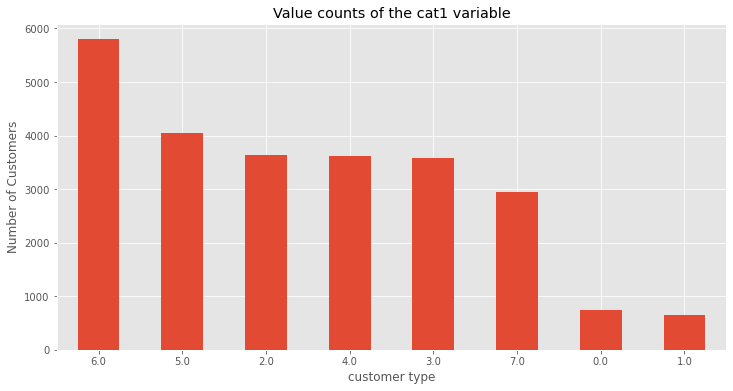

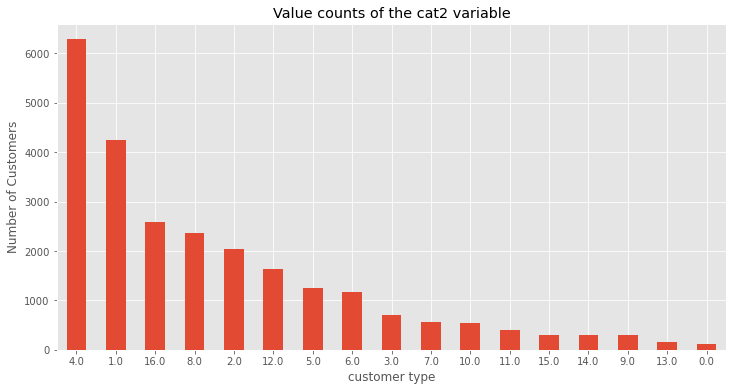

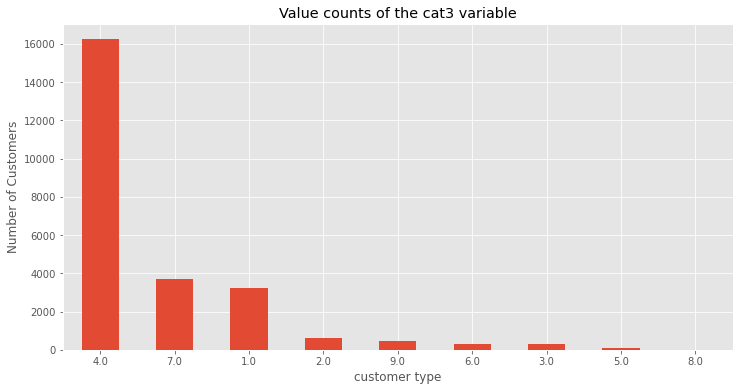

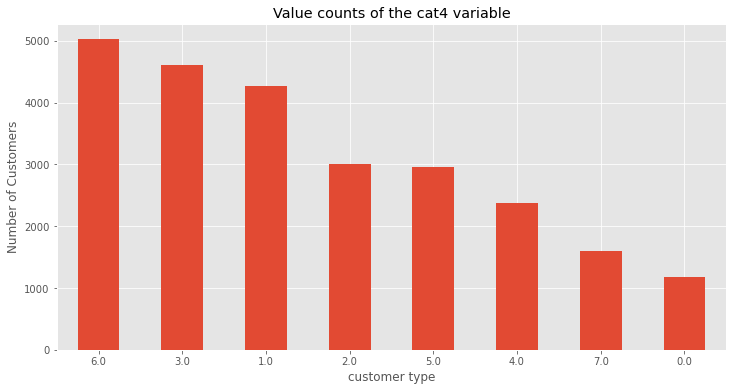

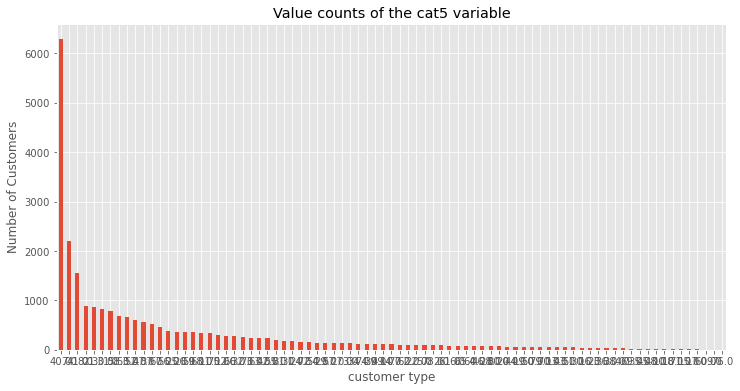

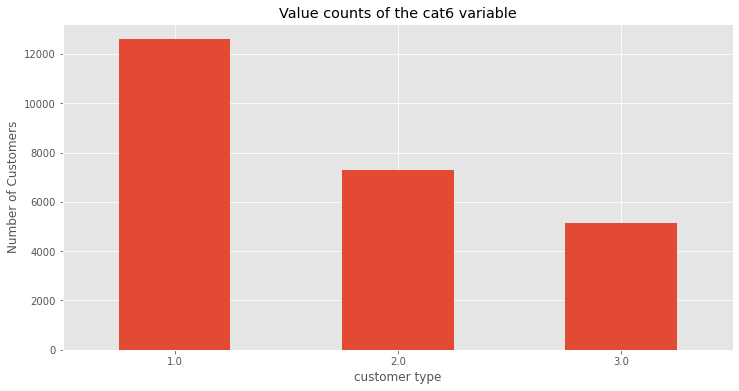

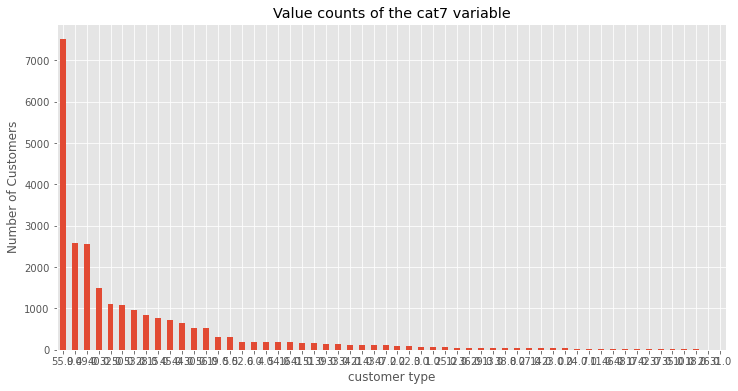

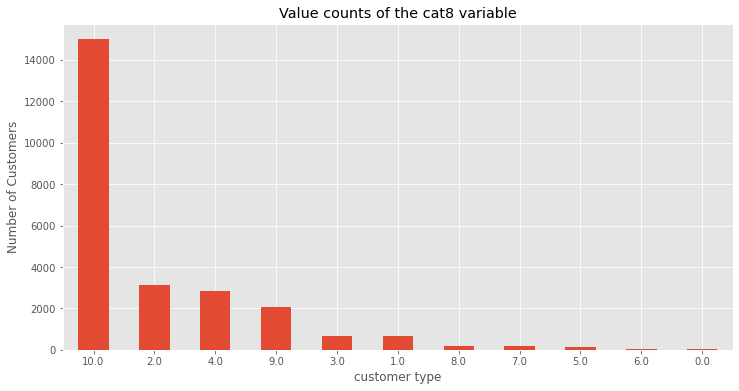

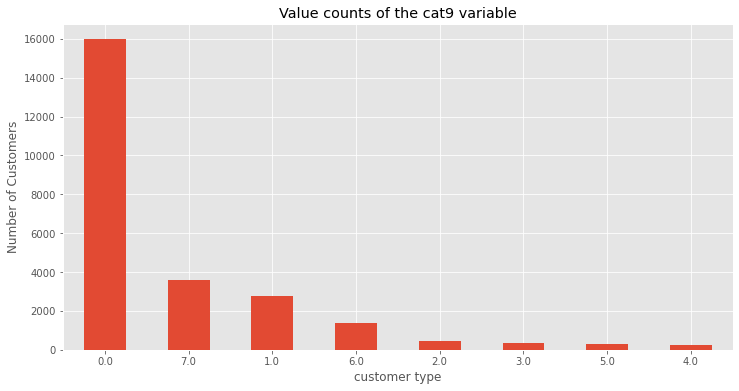

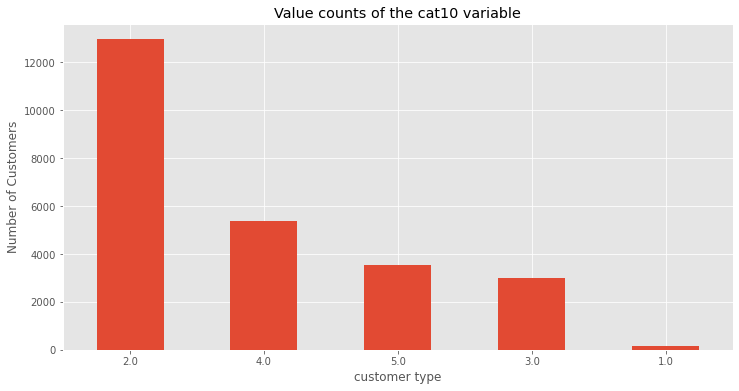

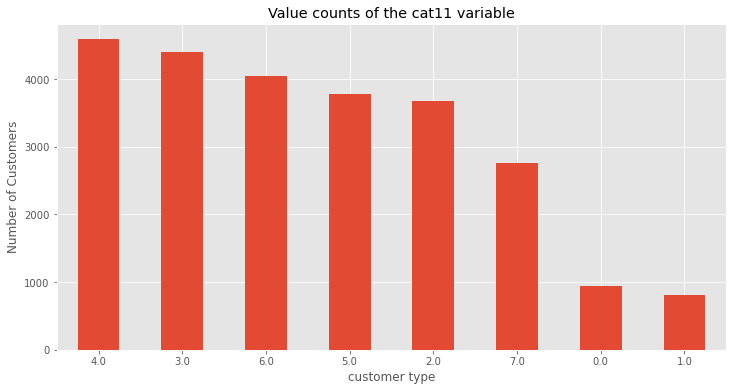

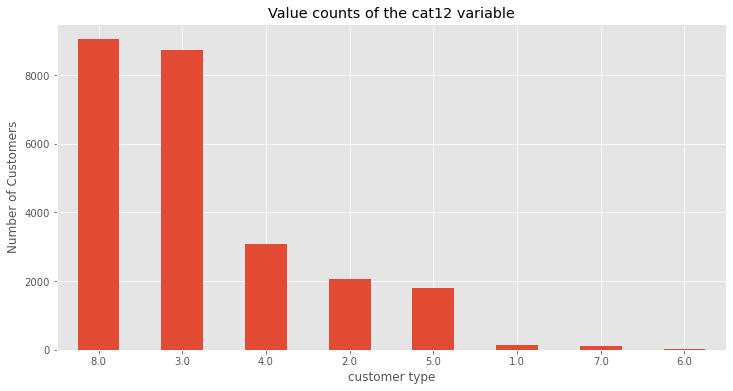

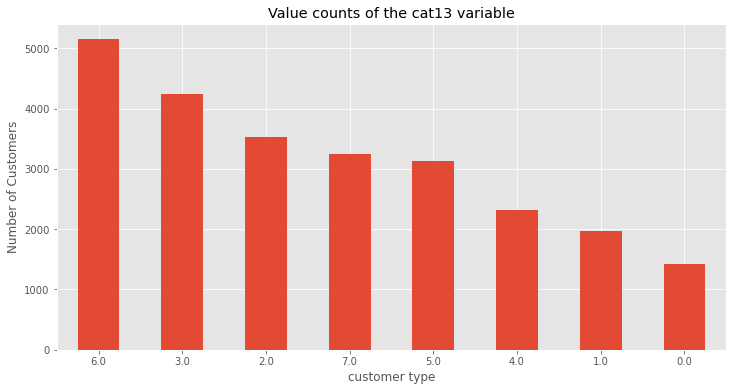

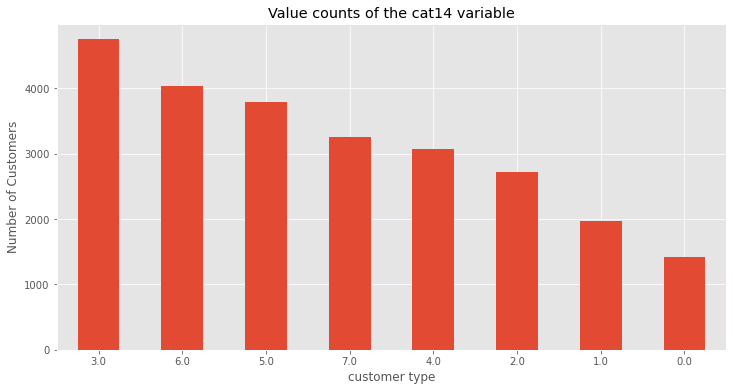

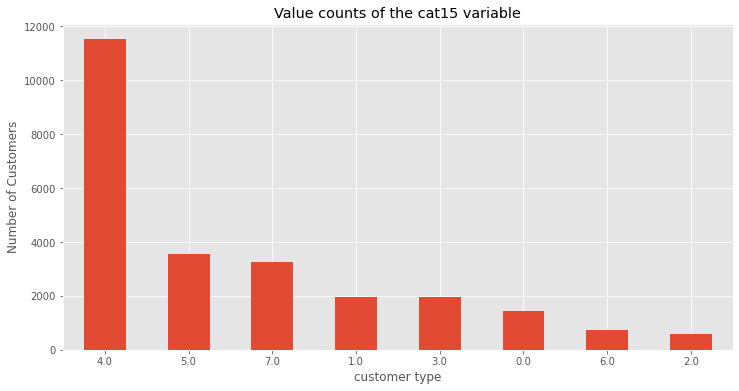

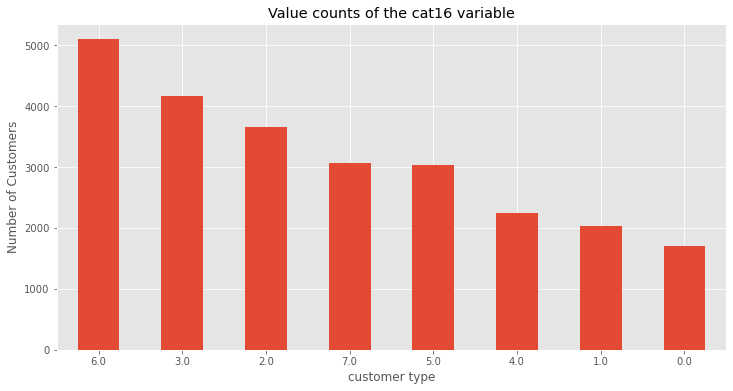

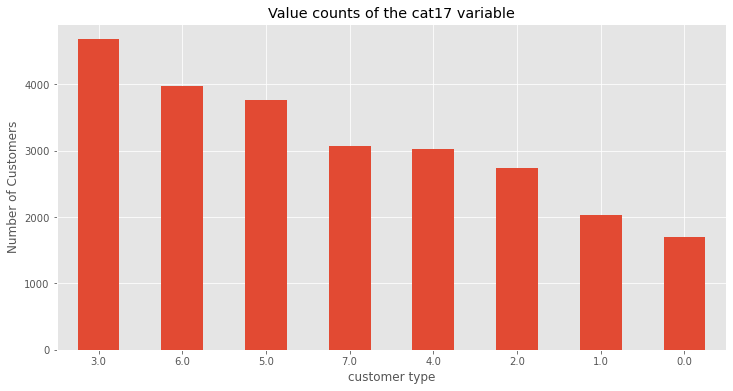

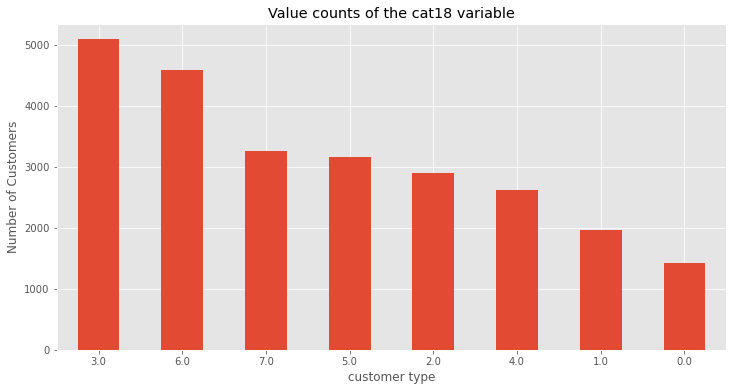

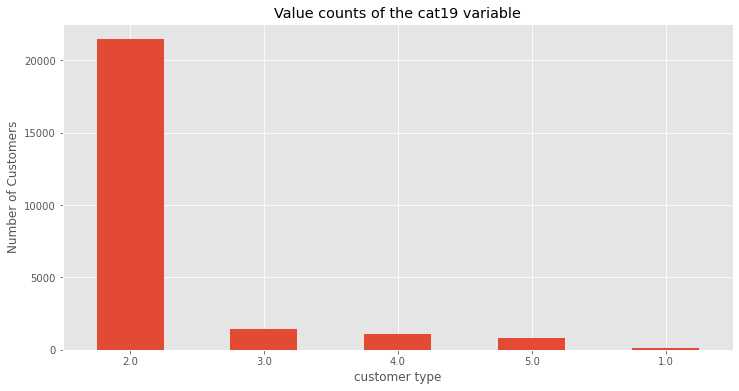

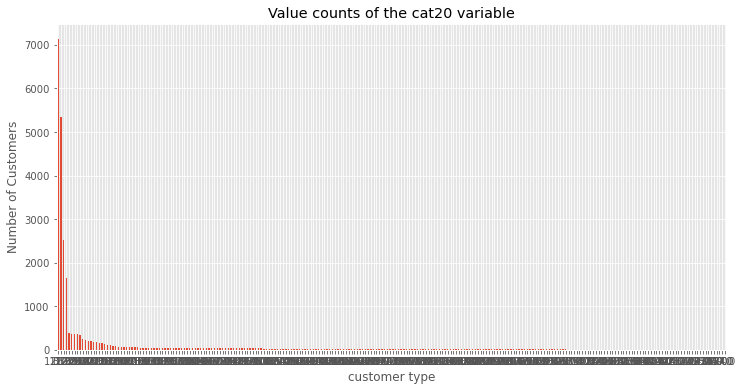

In [15]:
#for the remaining categorical variables starting with cat1 and ending with cat20
df.cat1.value_counts().plot(kind="bar")
plt.title("Value counts of the cat1 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat2.value_counts().plot(kind="bar")
plt.title("Value counts of the cat2 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat3.value_counts().plot(kind="bar")
plt.title("Value counts of the cat3 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat4.value_counts().plot(kind="bar")
plt.title("Value counts of the cat4 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat5.value_counts().plot(kind="bar")
plt.title("Value counts of the cat5 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat6.value_counts().plot(kind="bar")
plt.title("Value counts of the cat6 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat7.value_counts().plot(kind="bar")
plt.title("Value counts of the cat7 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat8.value_counts().plot(kind="bar")
plt.title("Value counts of the cat8 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat9.value_counts().plot(kind="bar")
plt.title("Value counts of the cat9 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat10.value_counts().plot(kind="bar")
plt.title("Value counts of the cat10 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat11.value_counts().plot(kind="bar")
plt.title("Value counts of the cat11 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat12.value_counts().plot(kind="bar")
plt.title("Value counts of the cat12 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()


df.cat13.value_counts().plot(kind="bar")
plt.title("Value counts of the cat13 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat14.value_counts().plot(kind="bar")
plt.title("Value counts of the cat14 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat15.value_counts().plot(kind="bar")
plt.title("Value counts of the cat15 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat16.value_counts().plot(kind="bar")
plt.title("Value counts of the cat16 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat17.value_counts().plot(kind="bar")
plt.title("Value counts of the cat17 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat18.value_counts().plot(kind="bar")
plt.title("Value counts of the cat18 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat19.value_counts().plot(kind="bar")
plt.title("Value counts of the cat19 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

df.cat20.value_counts().plot(kind="bar")
plt.title("Value counts of the cat20 variable")
plt.xlabel("customer type")
plt.xticks(rotation=0)
plt.ylabel("Number of Customers")
plt.show()

HEAT MAP FOR CATEGORIC VARIABLES

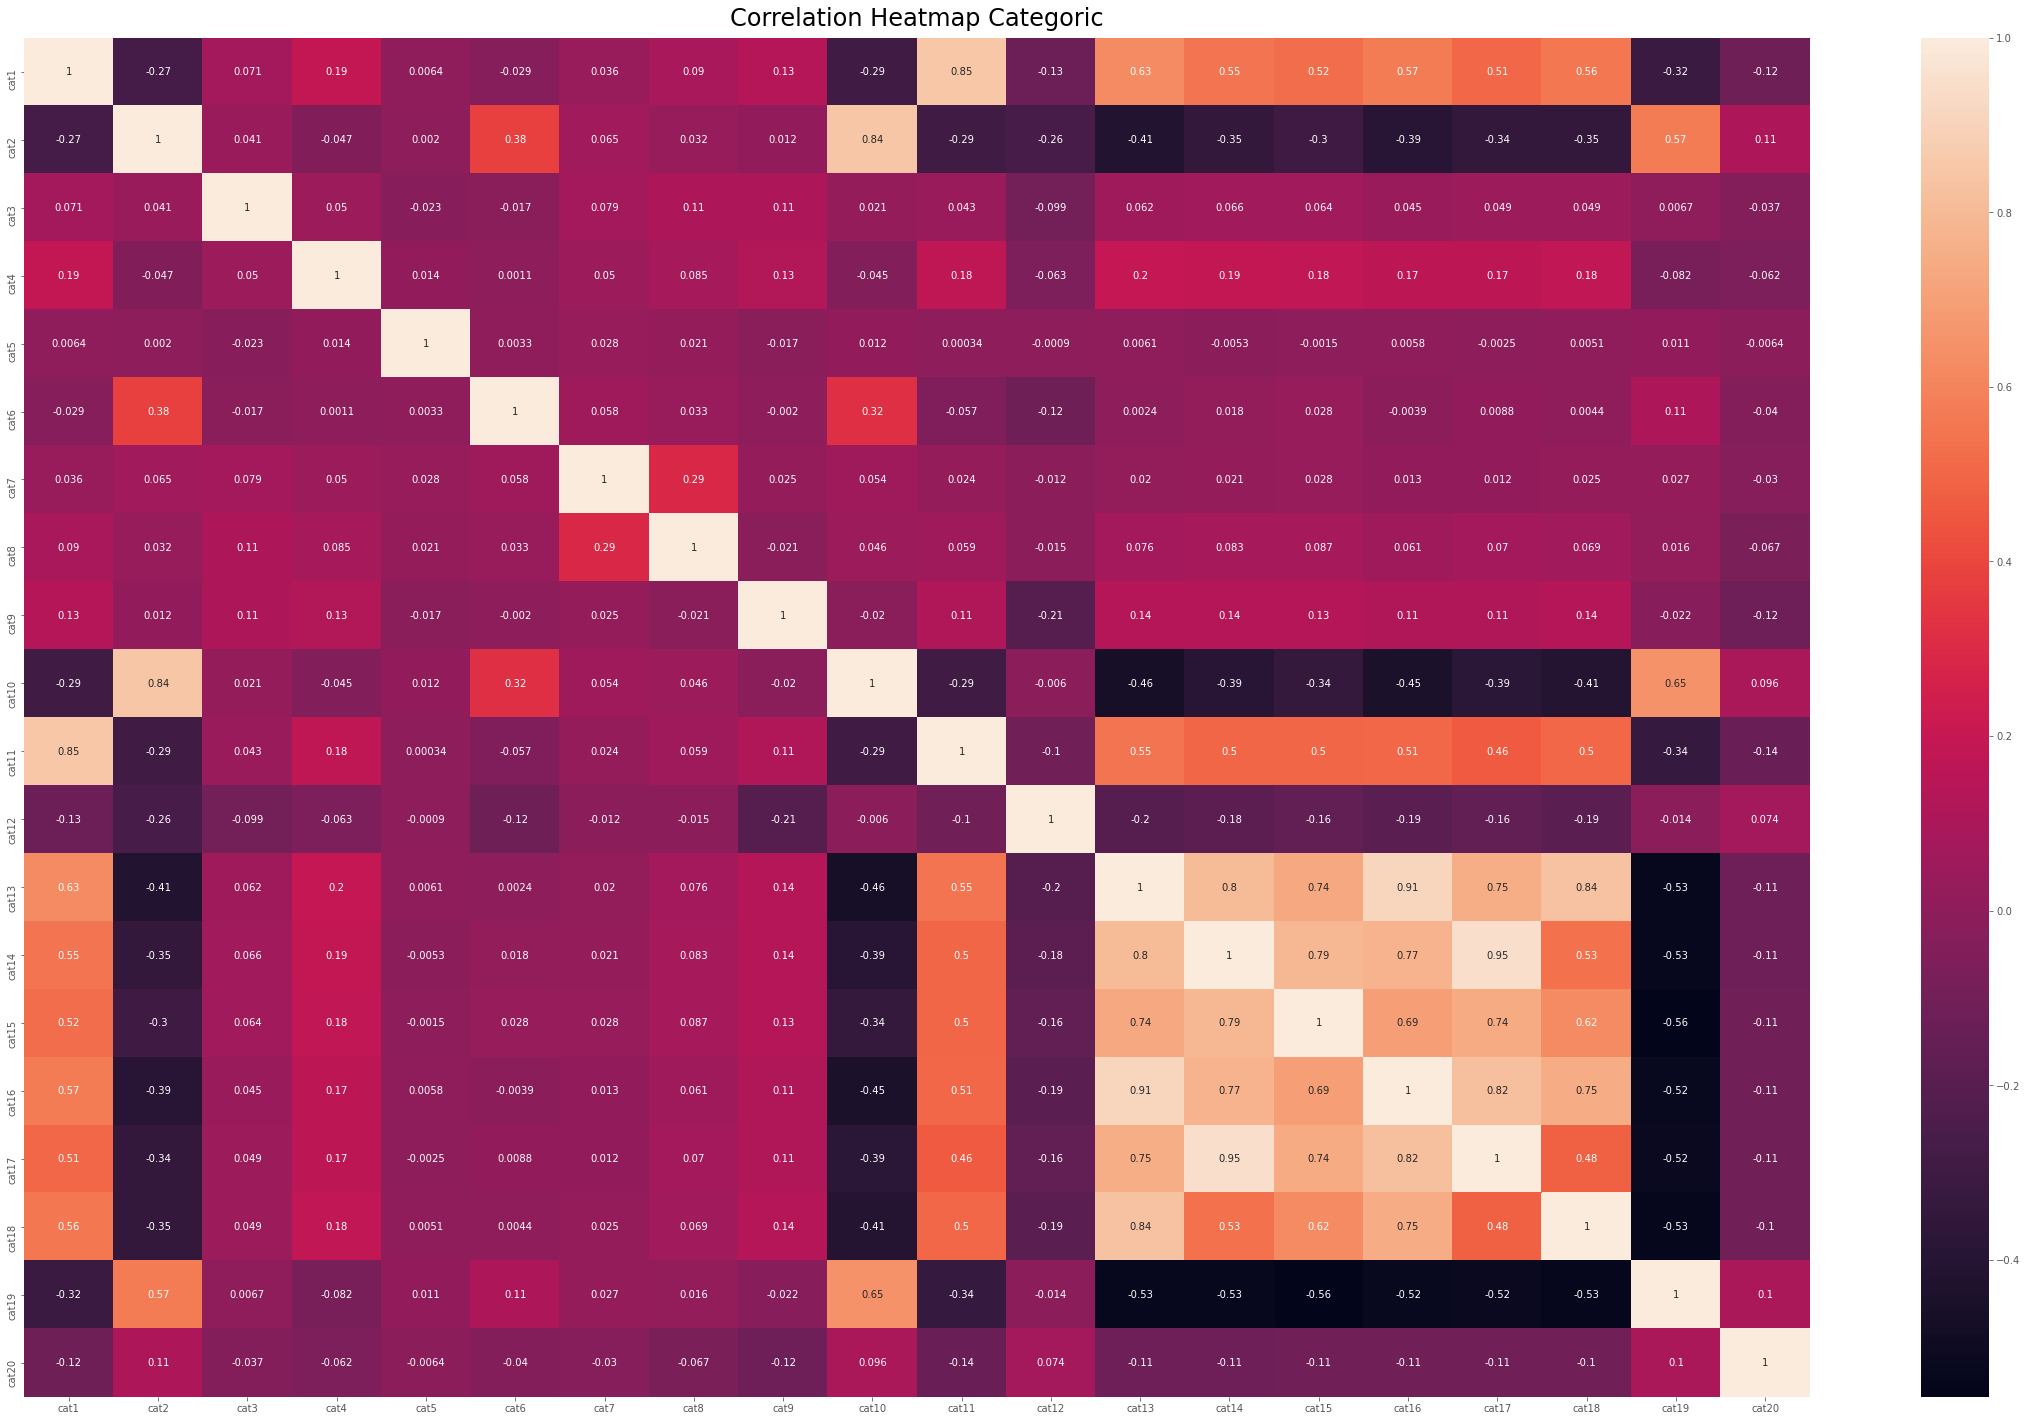

In [16]:
#heatmap for only categoric variables
data_cat = df.iloc[:,0:20]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_cat.corr(method='spearman'), annot=True,yticklabels=data_cat.columns,xticklabels=data_cat.columns)
heatmap.set_title('Correlation Heatmap Categoric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR CATEGORIC VARIABLES

Text(0.5, 1.0, 'CAT20')

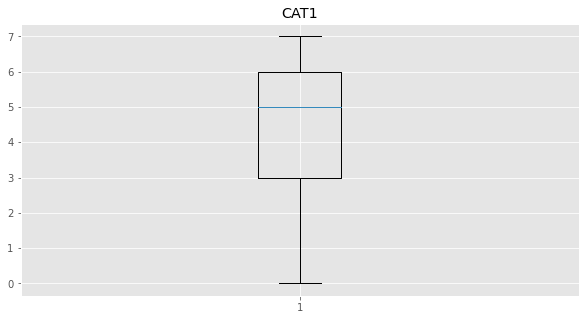

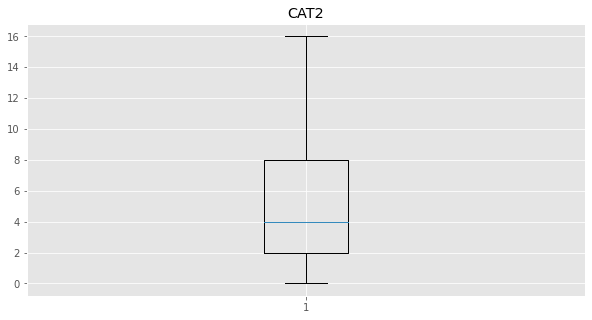

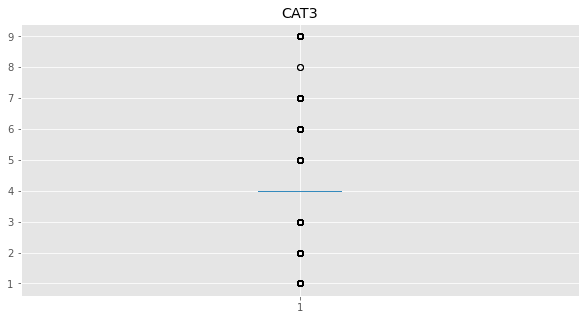

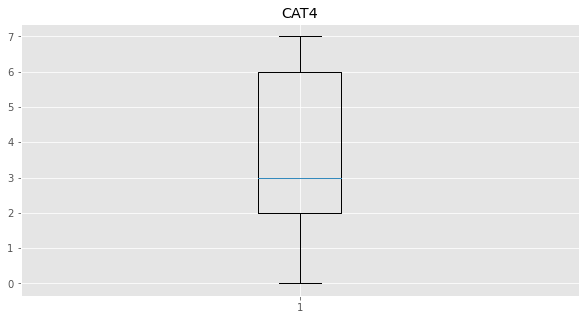

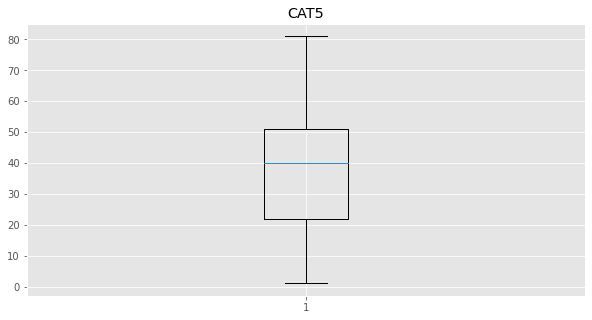

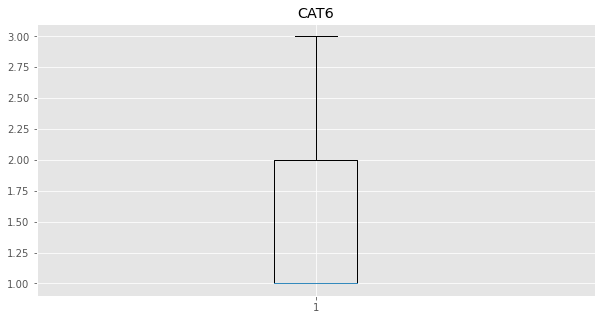

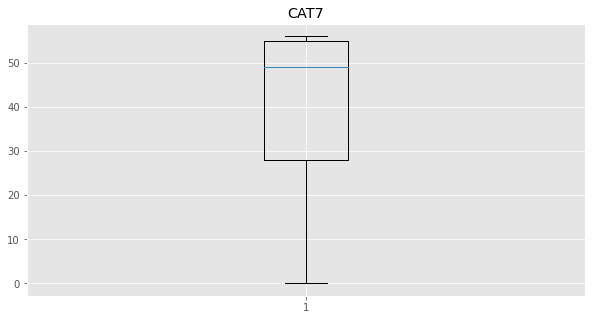

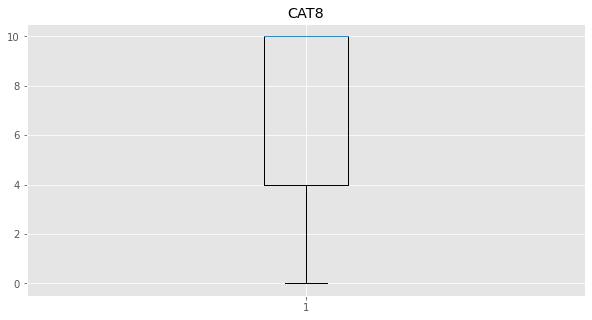

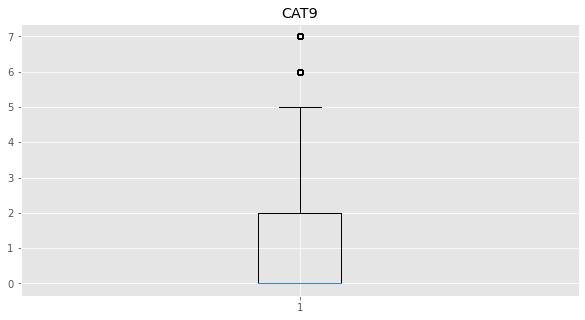

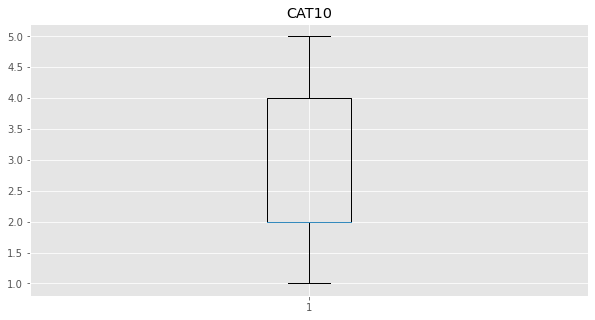

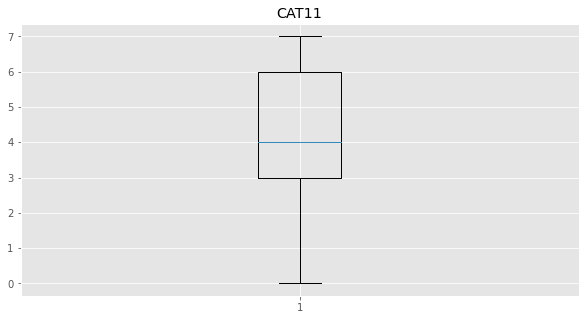

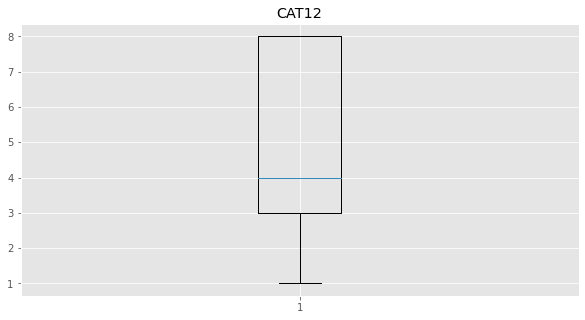

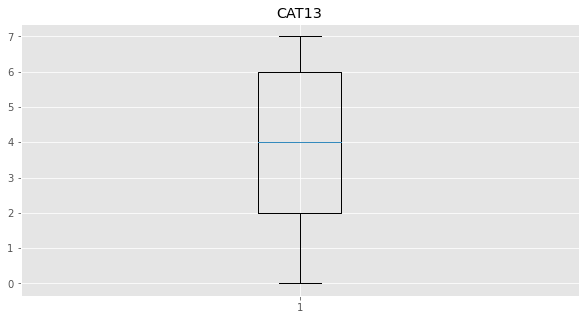

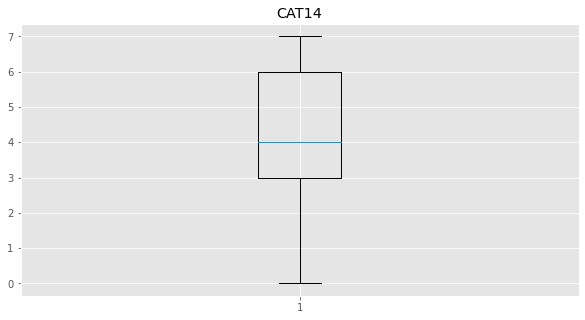

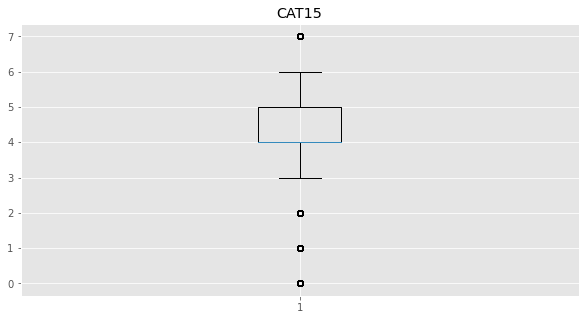

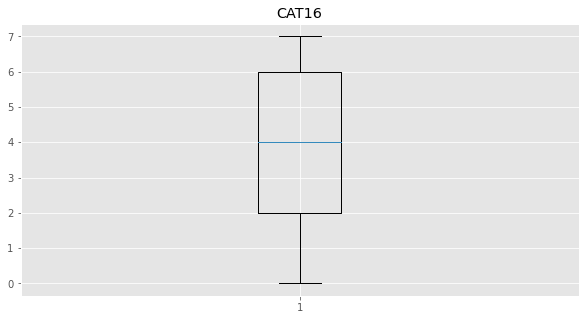

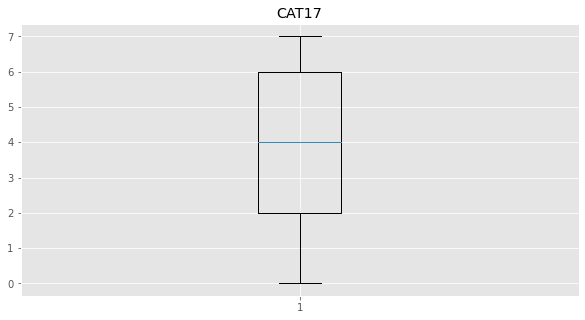

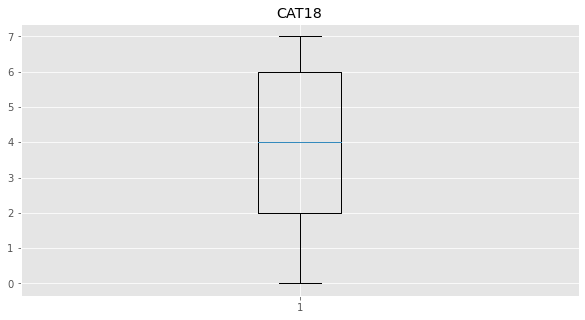

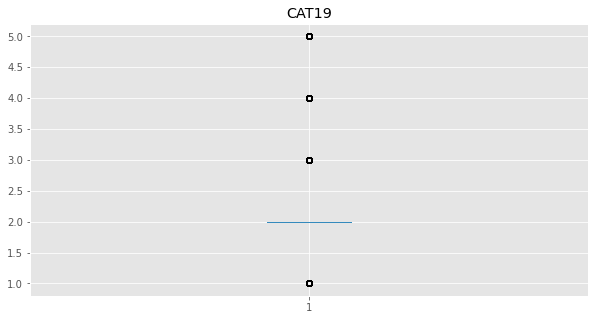

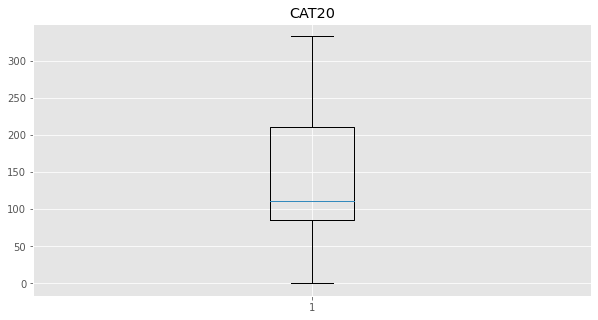

In [17]:
plt.figure(figsize=(10, 5))
plt.boxplot(df["cat1"])
plt.title('CAT1')
plt.figure(figsize=(10, 5))
plt.boxplot(df['cat2'])
plt.title('CAT2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat3'])
plt.title('CAT3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat4'])
plt.title('CAT4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat5'])
plt.title('CAT5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat6'])
plt.title('CAT6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat7'])
plt.title('CAT7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat8'])
plt.title('CAT8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat9'])
plt.title('CAT9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat10'])
plt.title('CAT10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat11'])
plt.title('CAT11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat12'])
plt.title('CAT12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat13'])
plt.title('CAT13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat14'])
plt.title('CAT14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat15'])
plt.title('CAT15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat16'])
plt.title('CAT16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat17'])
plt.title('CAT17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat18'])
plt.title('CAT18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['cat19'])
plt.title('CAT19')


plt.figure(figsize=(10, 5))
plt.boxplot(df['cat20'])
plt.title('CAT20')



GROUPED BOX PLOTS

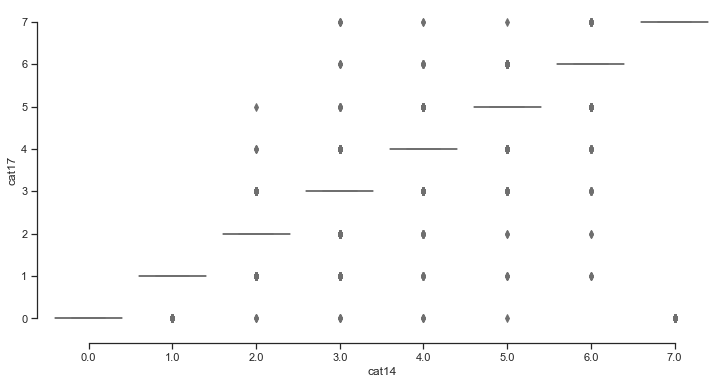

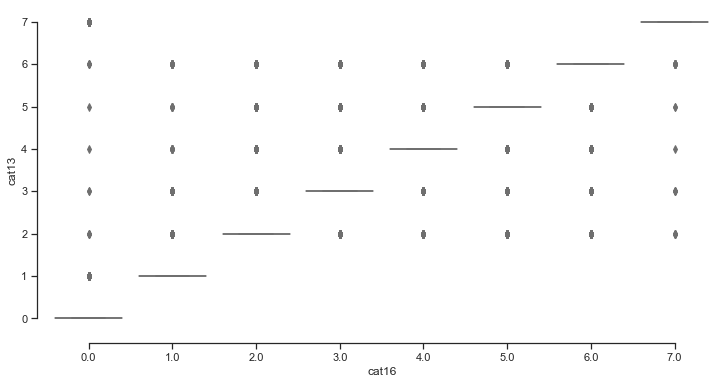

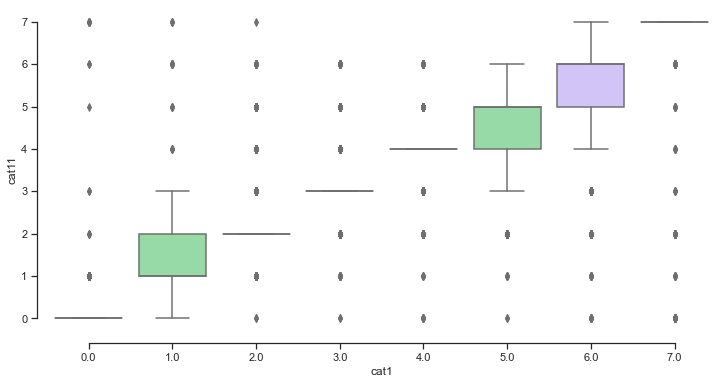

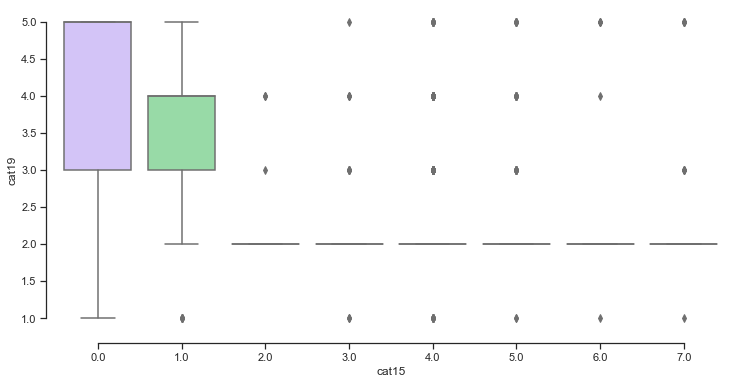

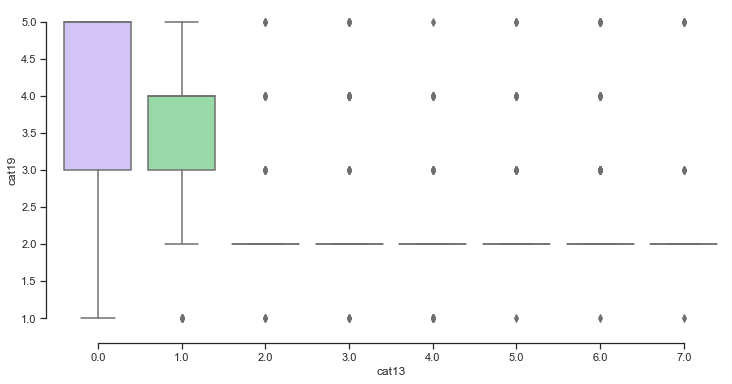

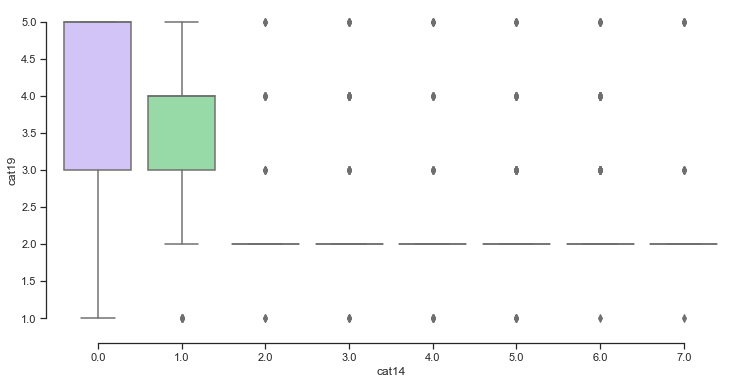

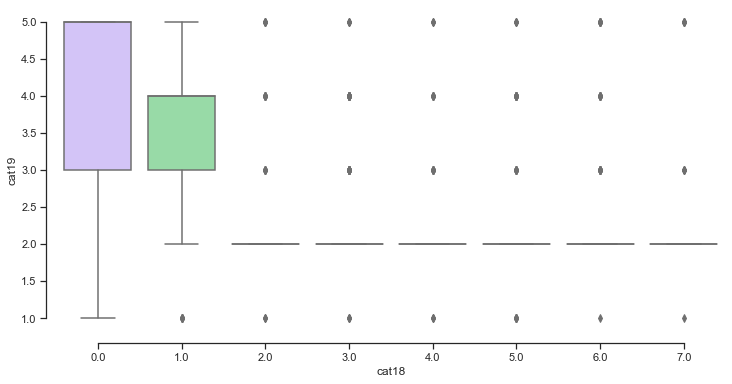

In [20]:
#STRONG CORRELATION
#positively correlated, corrletation: 0.95
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat14, y=df.cat17, palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#positively correlated, corrletation: 0.92
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat16, y=df.cat13,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#positively correlated, corrletation: 0.85
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat1, y=df.cat11,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()


#negatively correlated, corrletation: -0.55
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat15, y=df.cat19,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat13, y=df.cat19,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat14, y=df.cat19,
             palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()

#negatively correlated, corrletation: -0.53
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat18, y=df.cat19,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()



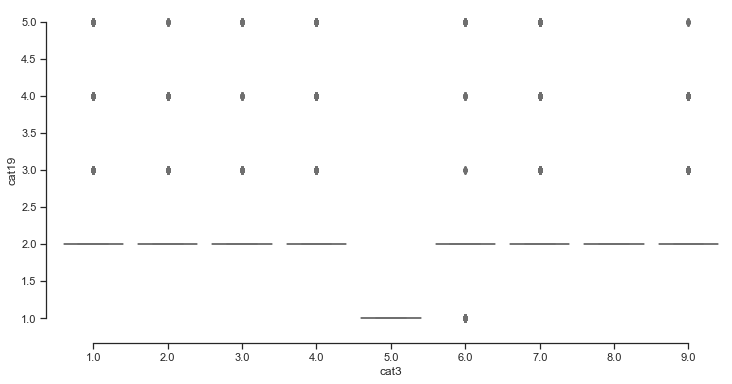

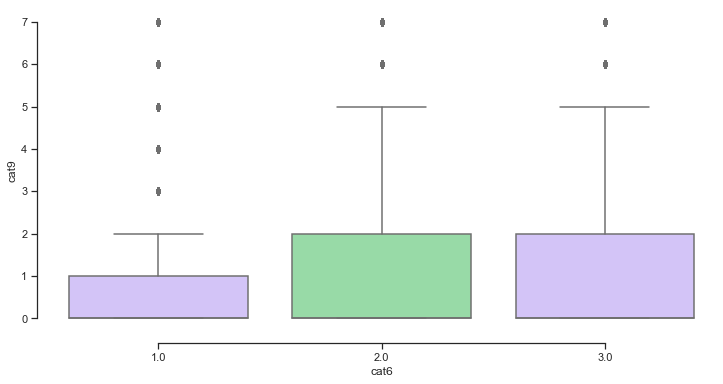

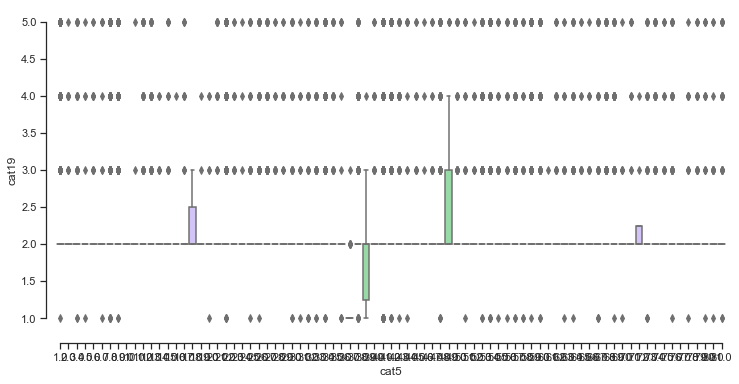

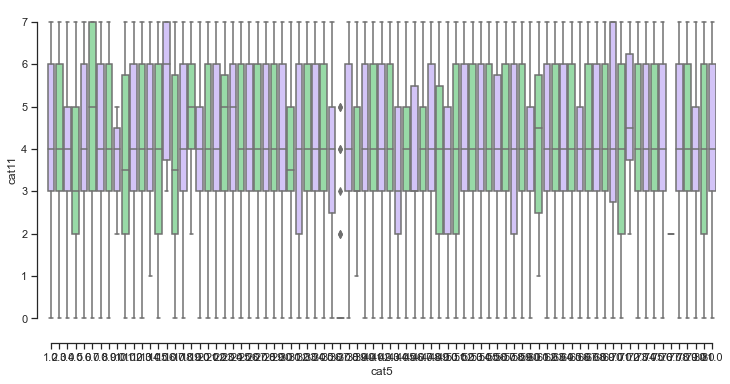

In [23]:
#very low correlated, corrletation: -0.0013
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat3, y=df.cat19,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()




#very low correlated, corrletation: -0.0024
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat6, y=df.cat9,
             palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()






#very low correlated, corrletation: -0.0009
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat5, y=df.cat19,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()





#very low correlated, corrletation: -0.00098
sns.set_theme(style="ticks", palette="pastel")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x= df.cat5, y=df.cat11,
            palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)
plt.show()



NUMERICAL VARIABLES

HISTOGRAMS

In [24]:
#define a function to get histogram of each column
def plot_histo(cstr, column):
    plt.hist(column)
    plt.title(cstr)
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.show()  
    
    # Add title and axis names


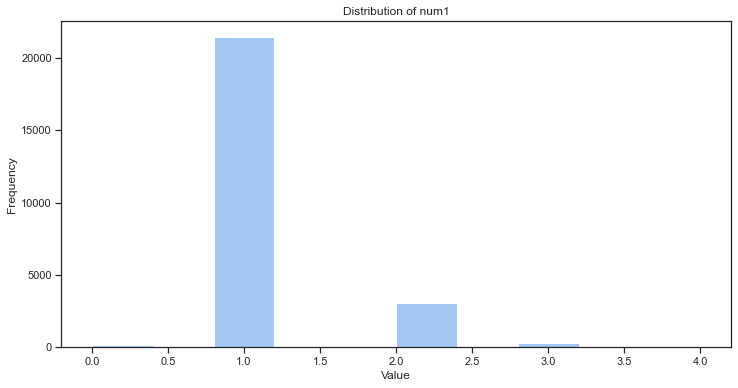

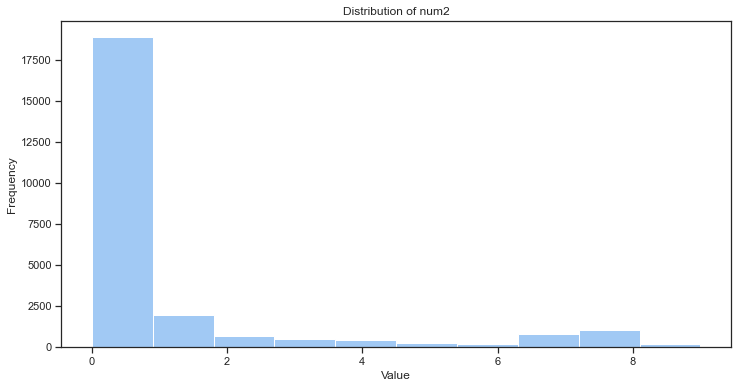

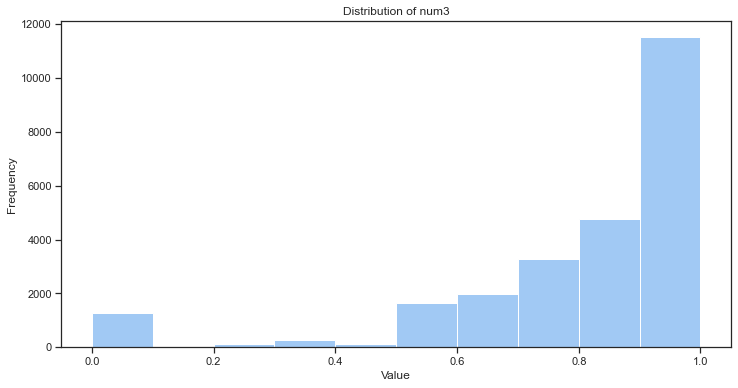

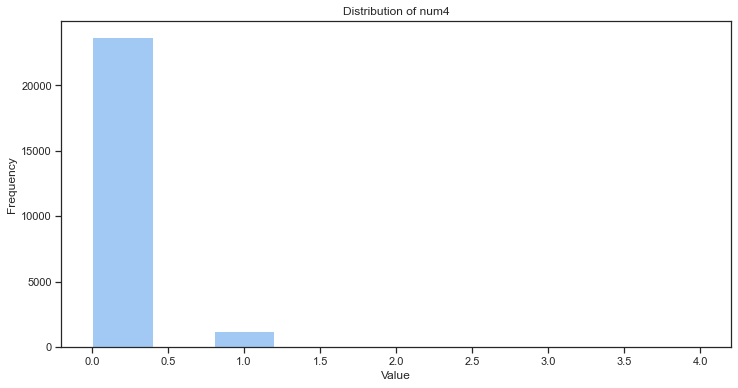

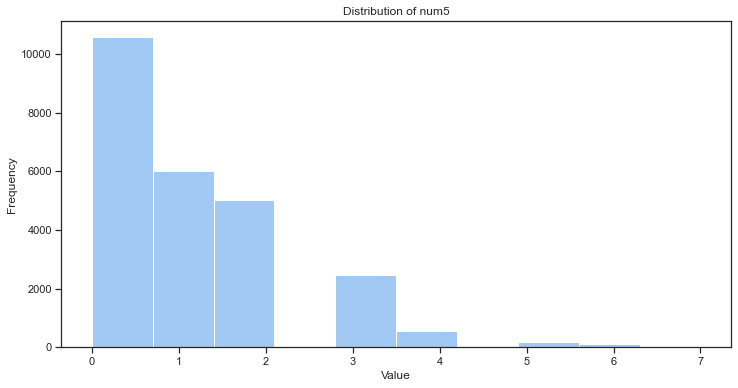

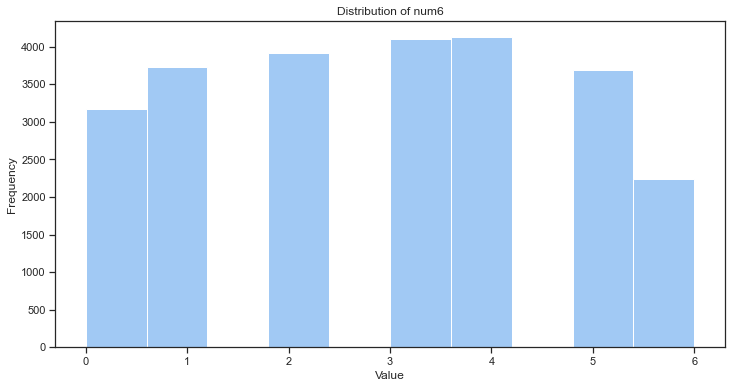

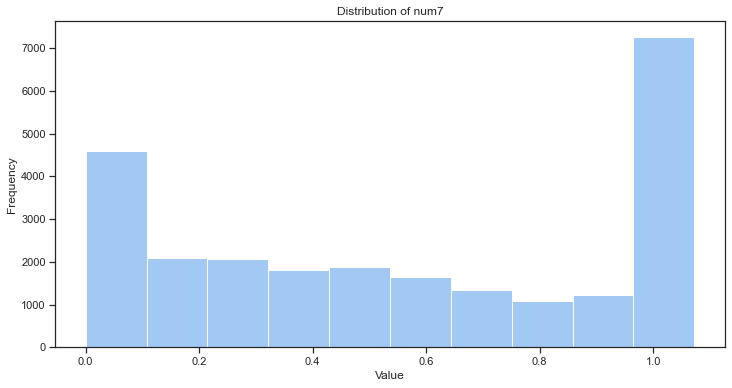

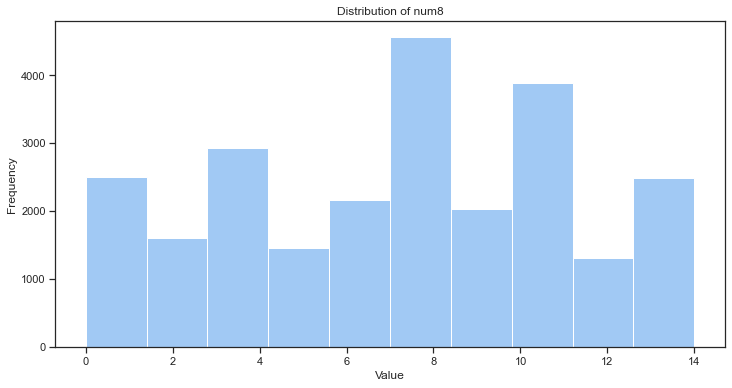

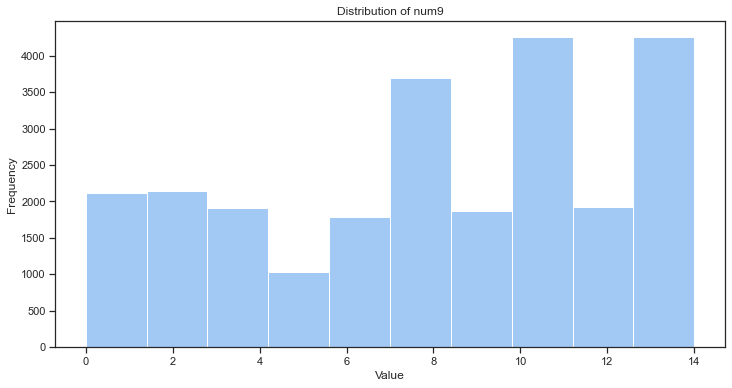

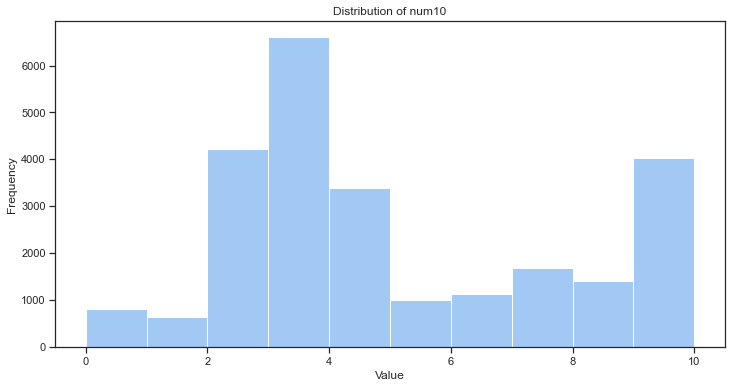

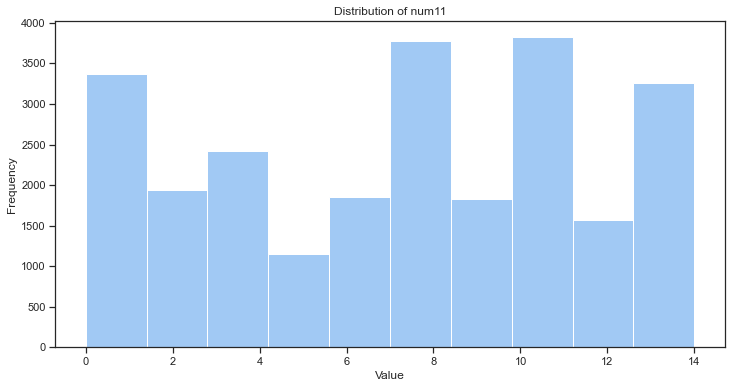

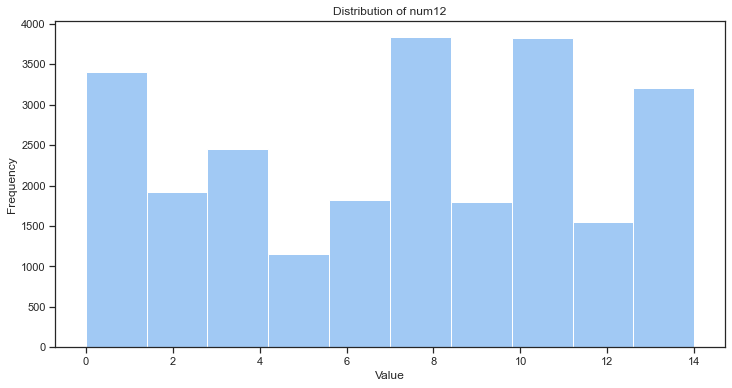

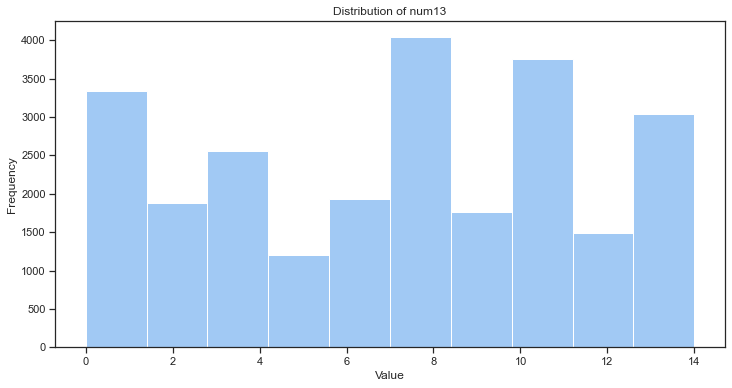

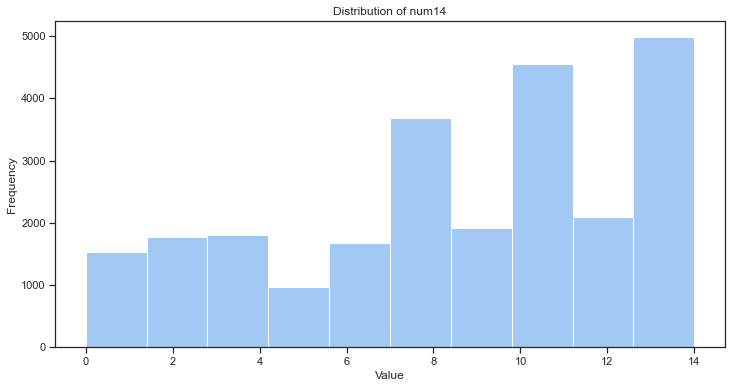

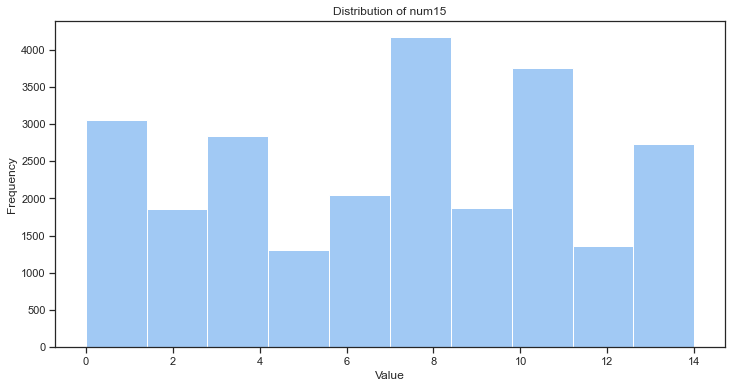

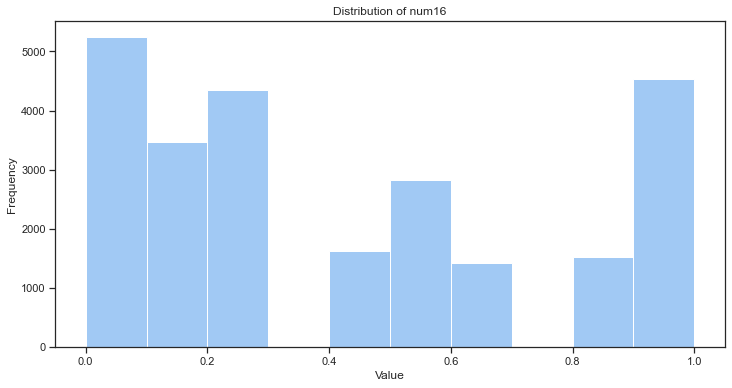

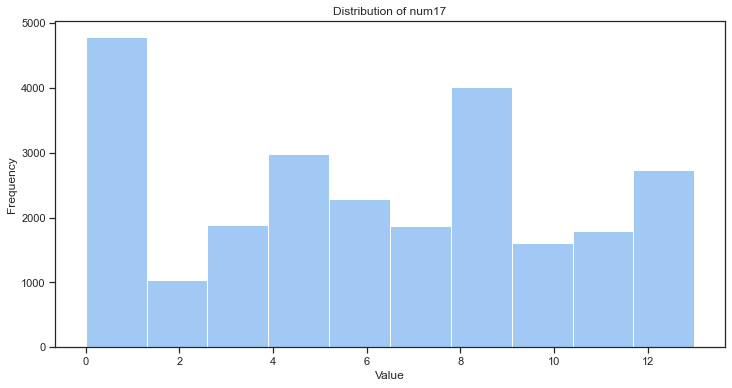

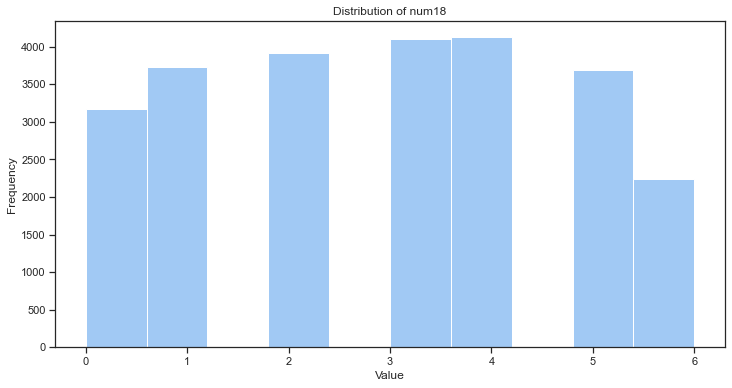

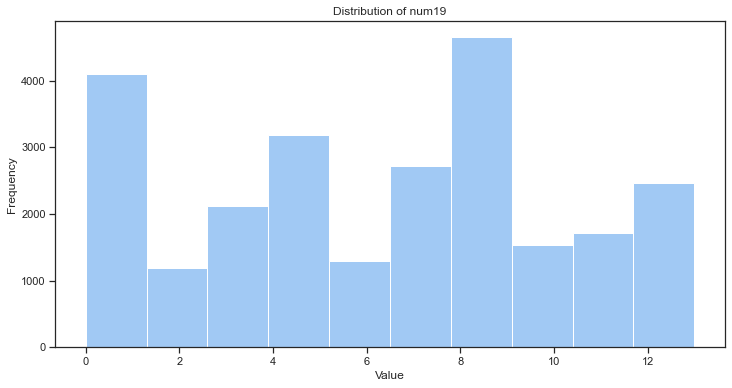

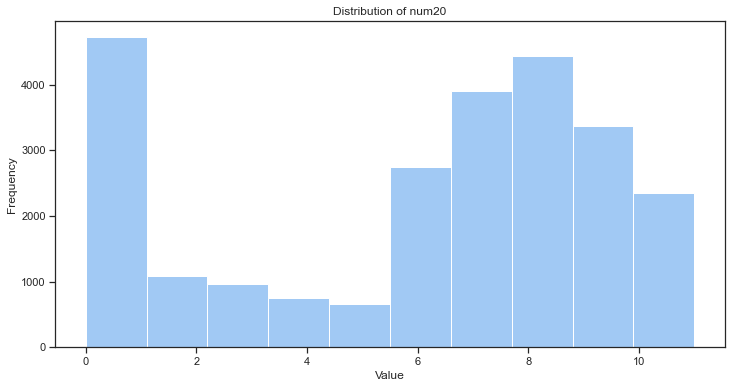

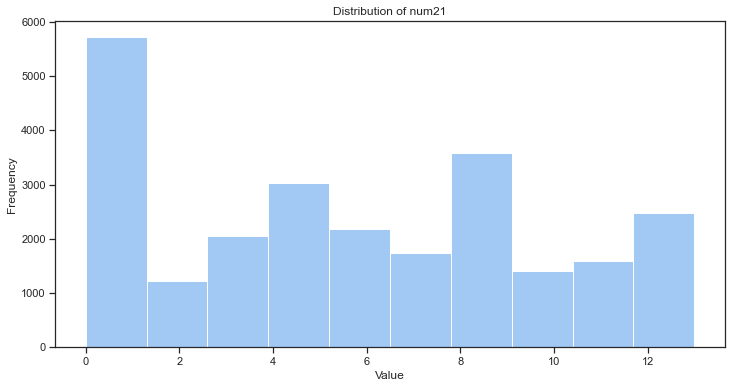

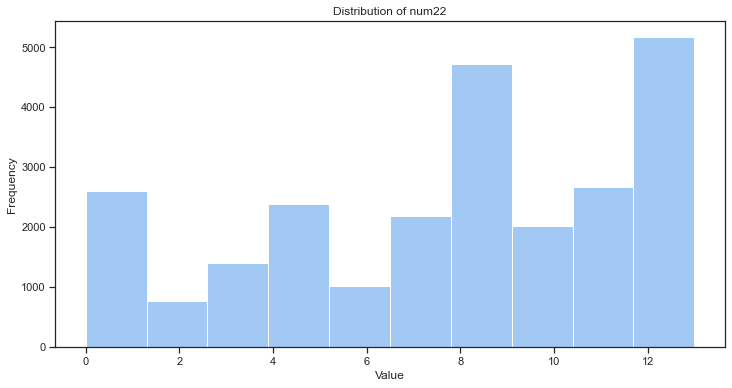

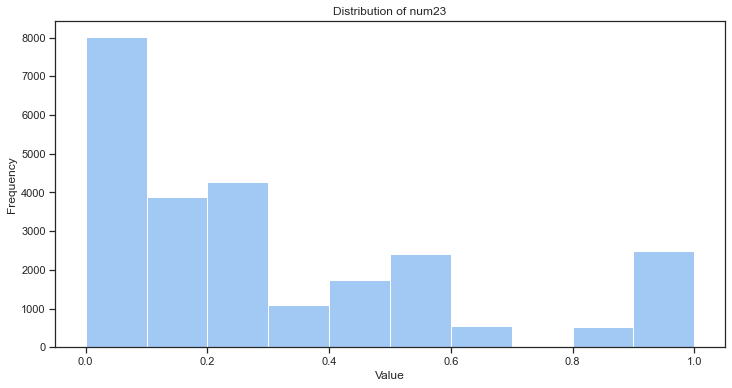

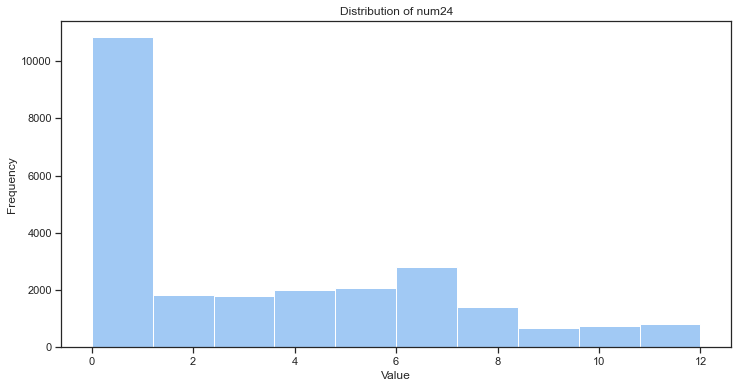

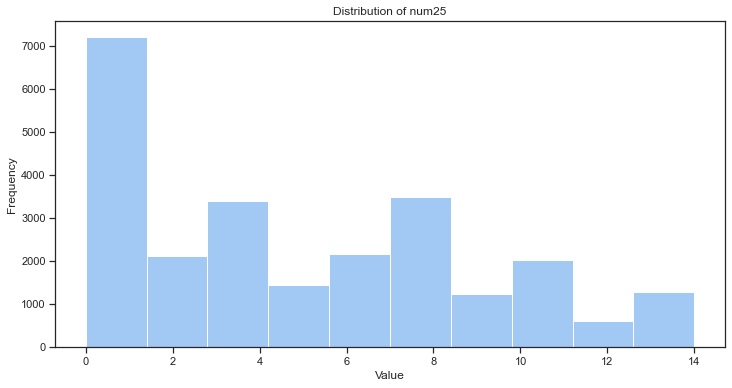

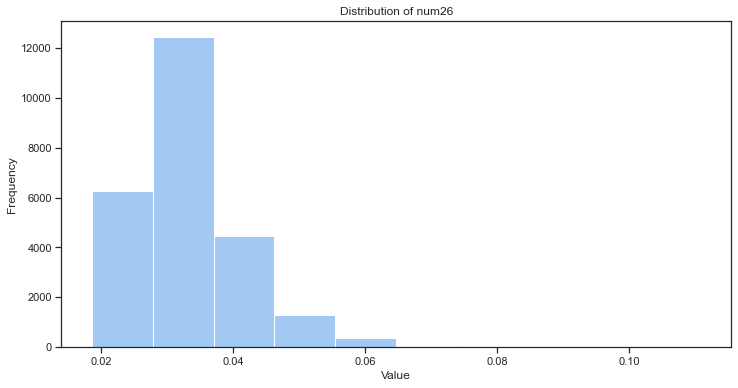

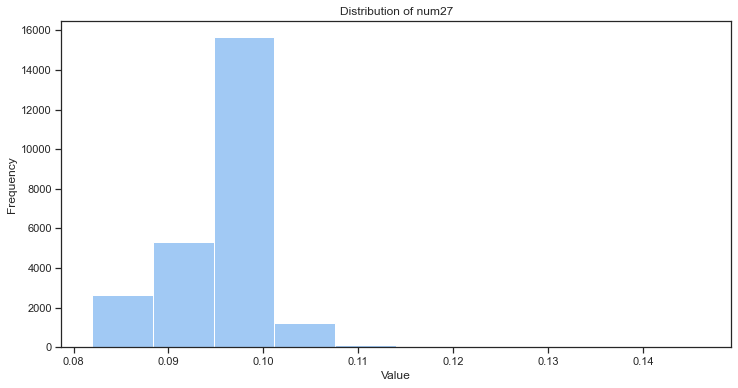

In [25]:
#numeric variables
#histo plot for numeric variables
df.num1.describe()
plot_histo("Distribution of num1", df.num1)

df.num2.describe()
plot_histo("Distribution of num2", df.num2)

df.num3.describe()
plot_histo("Distribution of num3", df.num3)

df.num4.describe()
plot_histo("Distribution of num4", df.num4)

df.num5.describe()
plot_histo("Distribution of num5", df.num5)

df.num6.describe()
plot_histo("Distribution of num6", df.num6)

df.num7.describe()
plot_histo("Distribution of num7", df.num7)

df.num8.describe()
plot_histo("Distribution of num8", df.num8)

df.num9.describe()
plot_histo("Distribution of num9", df.num9)

df.num10.describe()
plot_histo("Distribution of num10", df.num10)

df.num11.describe()
plot_histo("Distribution of num11", df.num11)

df.num12.describe()
plot_histo("Distribution of num12", df.num12)

df.num13.describe()
plot_histo("Distribution of num13", df.num13)

df.num14.describe()
plot_histo("Distribution of num14", df.num14)

df.num15.describe()
plot_histo("Distribution of num15", df.num15)

df.num16.describe()
plot_histo("Distribution of num16", df.num16)

df.num17.describe()
plot_histo("Distribution of num17", df.num17)

df.num18.describe()
plot_histo("Distribution of num18", df.num18)

df.num19.describe()
plot_histo("Distribution of num19", df.num19)

df.num20.describe()
plot_histo("Distribution of num20", df.num20)

df.num21.describe()
plot_histo("Distribution of num21", df.num21)

df.num22.describe()
plot_histo("Distribution of num22", df.num22)

df.num23.describe()
plot_histo("Distribution of num23", df.num23)

df.num24.describe()
plot_histo("Distribution of num24", df.num24)

df.num25.describe()
plot_histo("Distribution of num25", df.num25)

df.num26.describe()
plot_histo("Distribution of num26", df.num26)

df.num27.describe()
plot_histo("Distribution of num27", df.num27)


HEAT MAP FOR NUMERIC VARIABLES

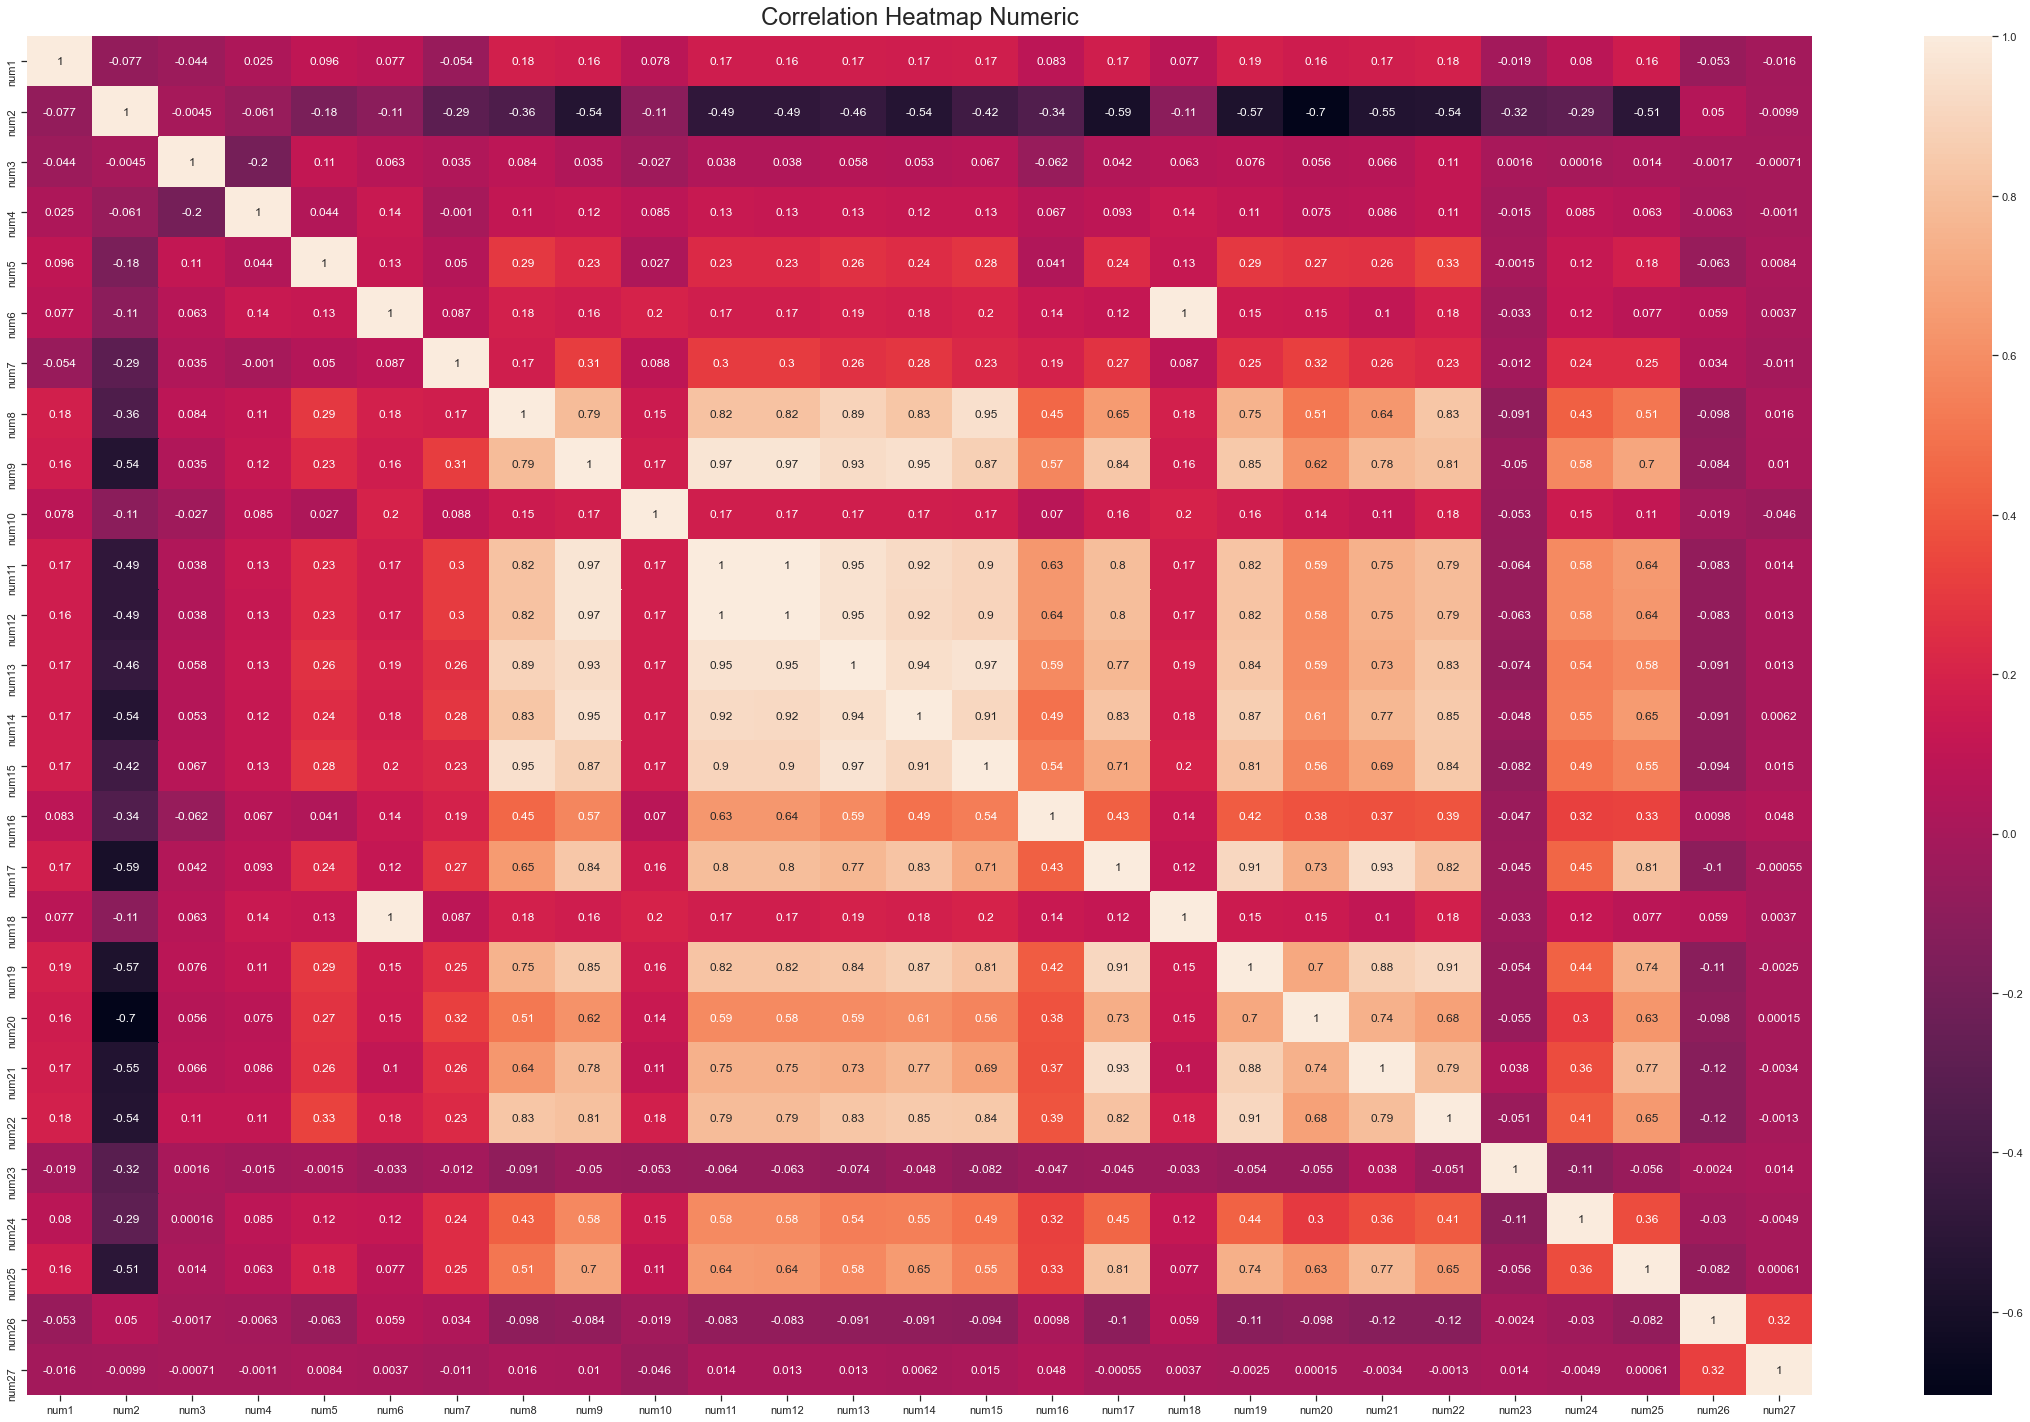

In [26]:
#heat map only for numeric variables
data_num = df.iloc[:,20:47]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data_num.corr(), annot=True,yticklabels=data_num.columns,xticklabels=data_num.columns)
heatmap.set_title('Correlation Heatmap Numeric', fontdict={'fontsize':24}, pad=12);

BOX PLOT FOR NUMERIC VARIABLES

<ipython-input-28-73f476cf5686>:81: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(10, 5))


Text(0.5, 1.0, 'NUM27')

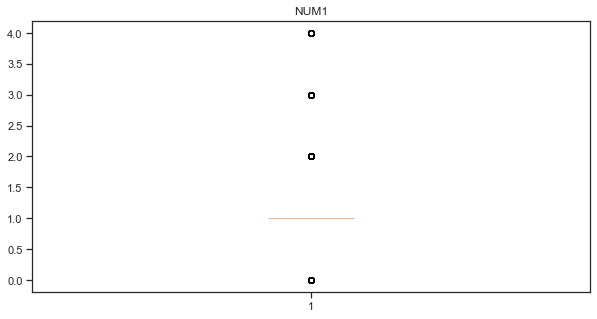

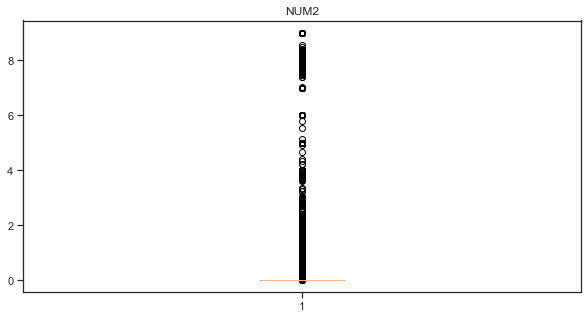

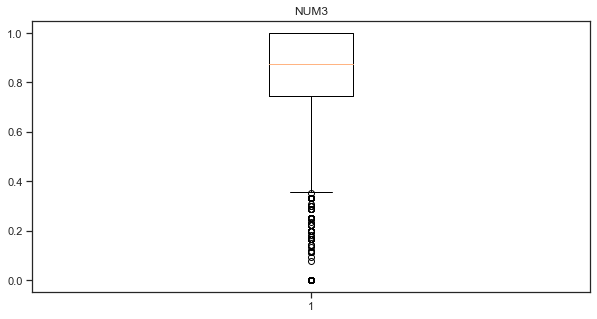

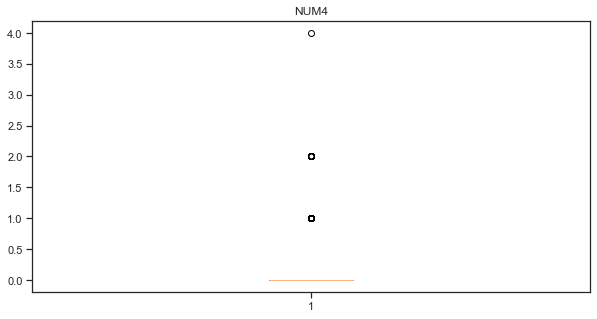

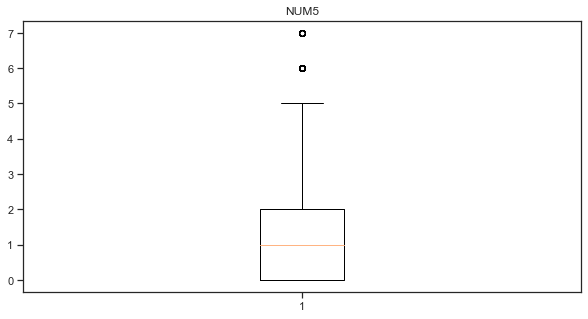

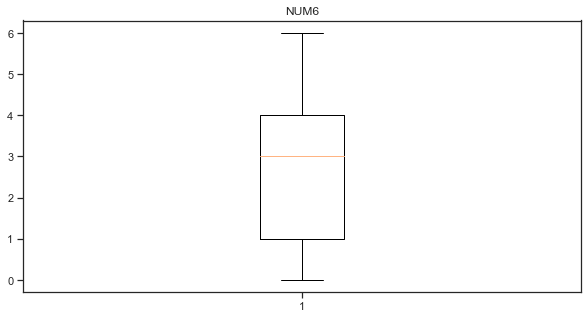

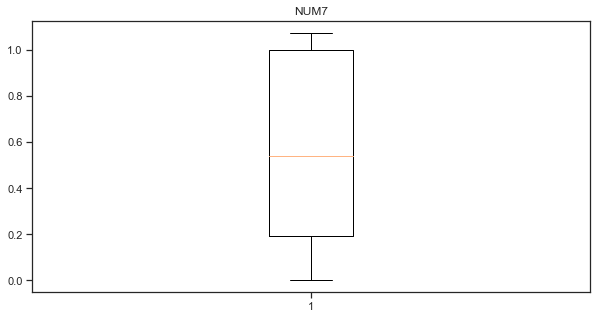

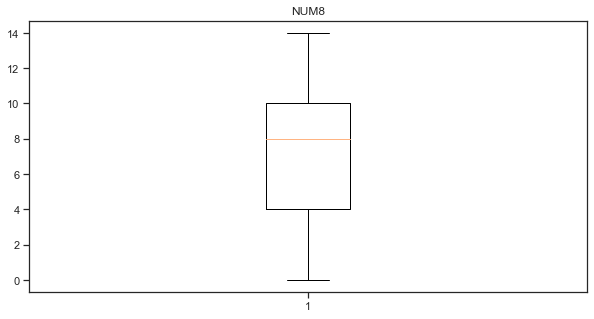

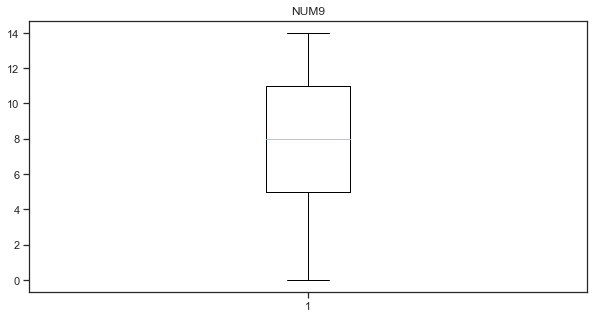

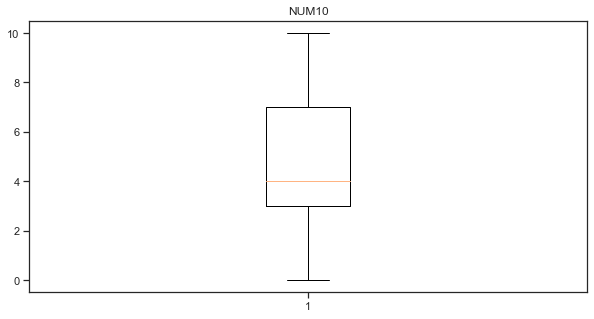

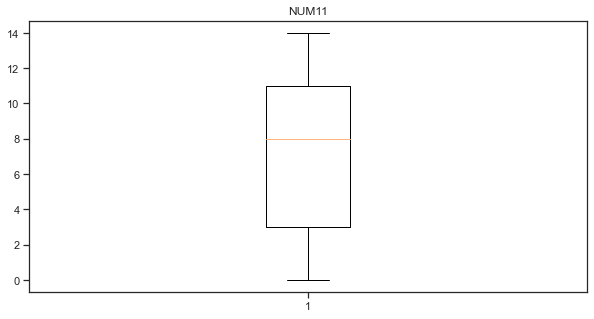

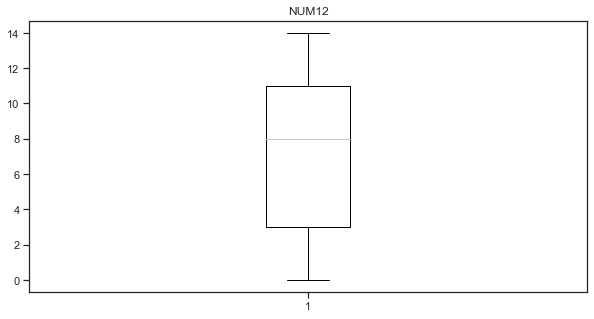

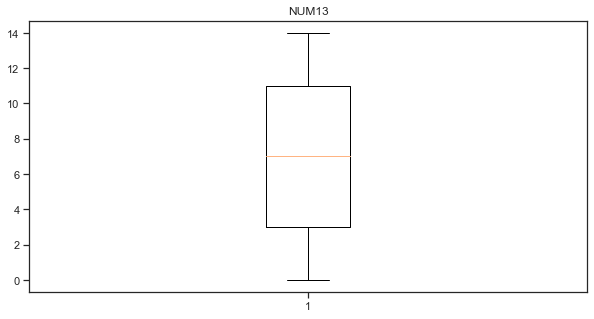

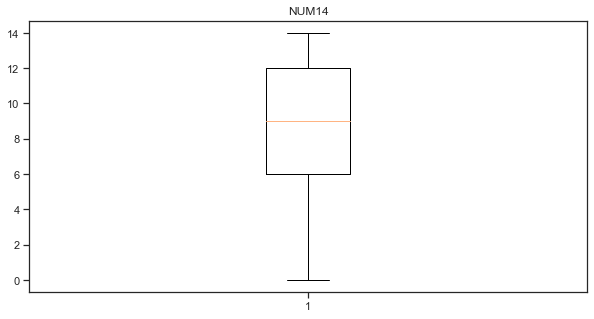

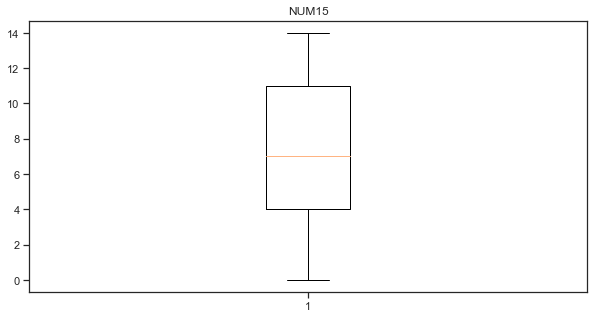

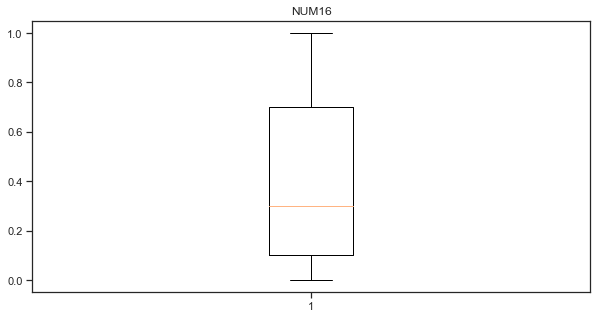

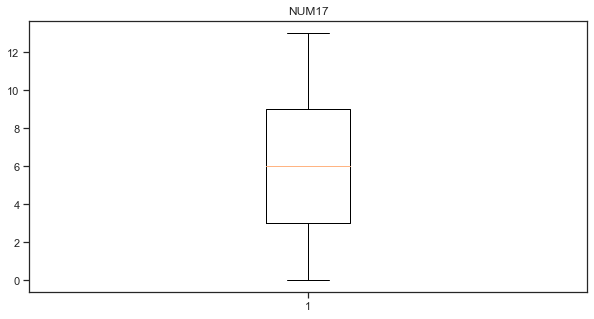

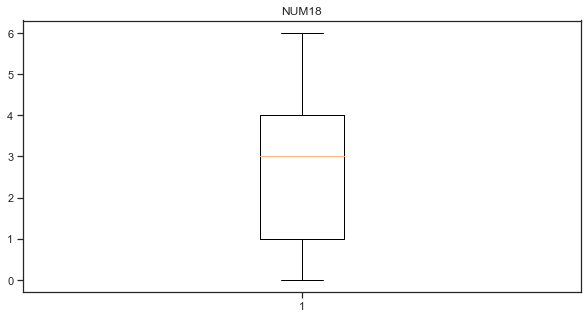

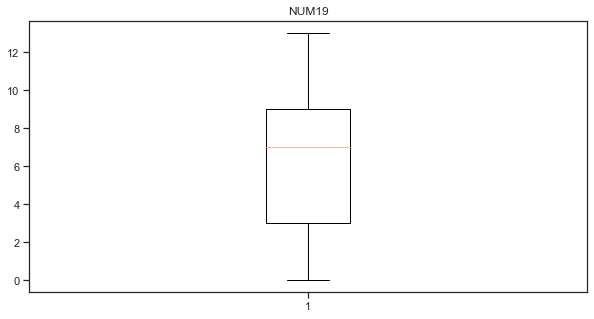

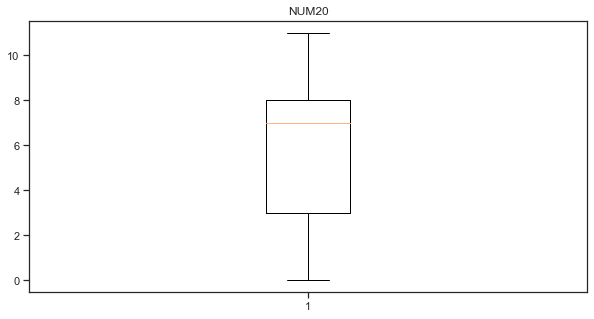

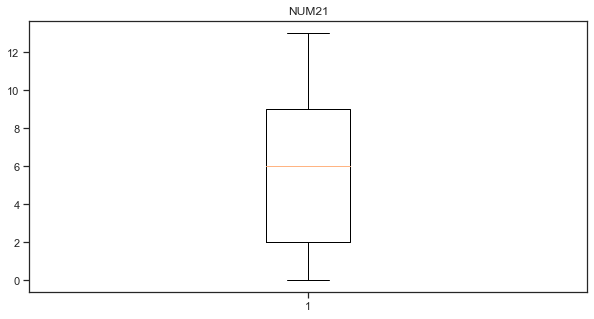

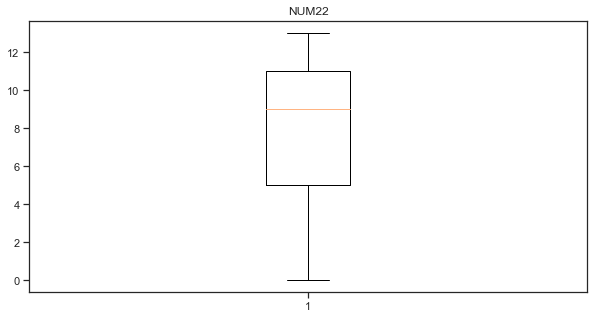

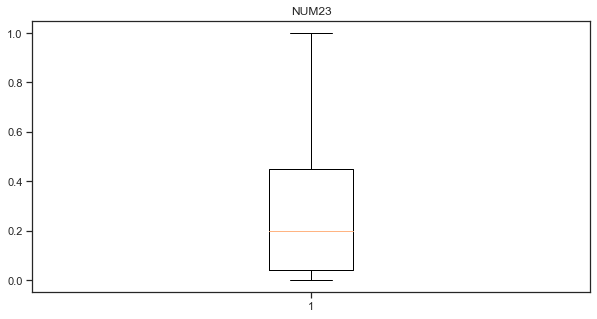

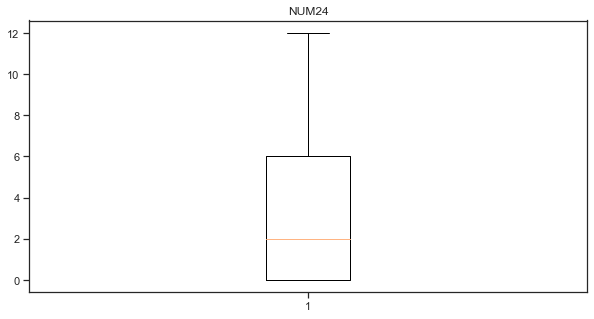

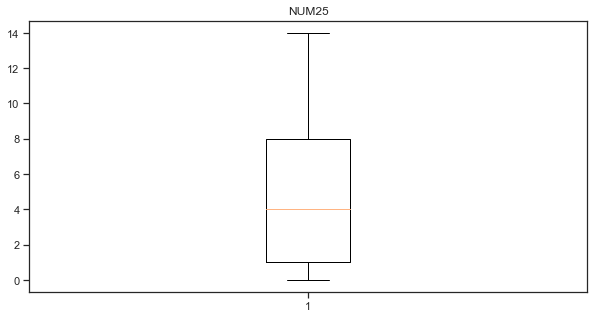

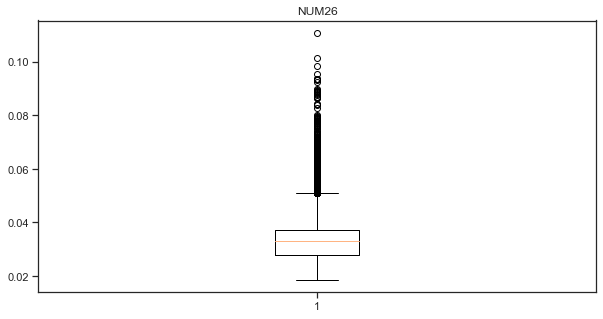

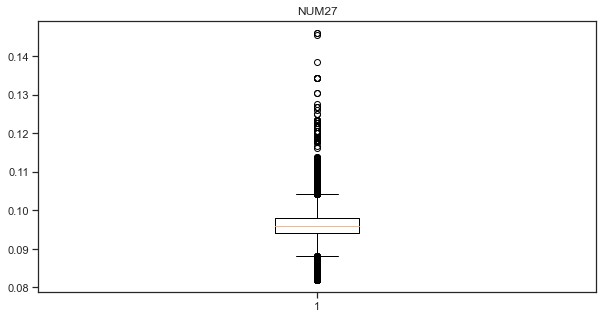

In [28]:


plt.figure(figsize=(10, 5))
plt.boxplot(df['num1'])
plt.title('NUM1')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num2'])
plt.title('NUM2')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num3'])
plt.title('NUM3')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num4'])
plt.title('NUM4')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num5'])
plt.title('NUM5')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num6'])
plt.title('NUM6')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num7'])
plt.title('NUM7')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num8'])
plt.title('NUM8')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num9'])
plt.title('NUM9')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num10'])
plt.title('NUM10')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num11'])
plt.title('NUM11')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num12'])
plt.title('NUM12')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num13'])
plt.title('NUM13')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num14'])
plt.title('NUM14')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num15'])
plt.title('NUM15')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num16'])
plt.title('NUM16')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num17'])
plt.title('NUM17')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num18'])
plt.title('NUM18')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num19'])
plt.title('NUM19')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num20'])
plt.title('NUM20')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num21'])
plt.title('NUM21')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num22'])
plt.title('NUM22')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num23'])
plt.title('NUM23')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num24'])
plt.title('NUM24')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num25'])
plt.title('NUM25')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num26'])
plt.title('NUM26')

plt.figure(figsize=(10, 5))
plt.boxplot(df['num27'])
plt.title('NUM27')





SCATTERPLOT FOR NUMERIC X NUMERIC

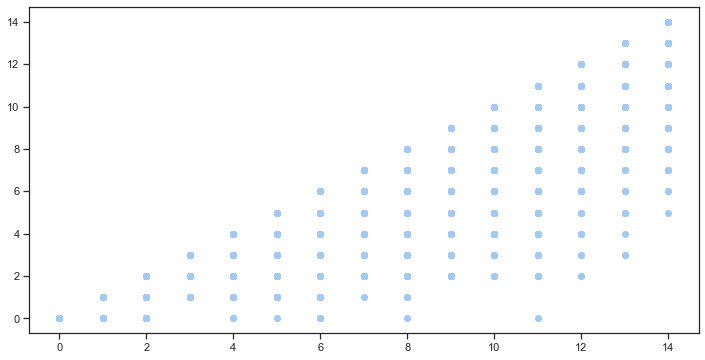

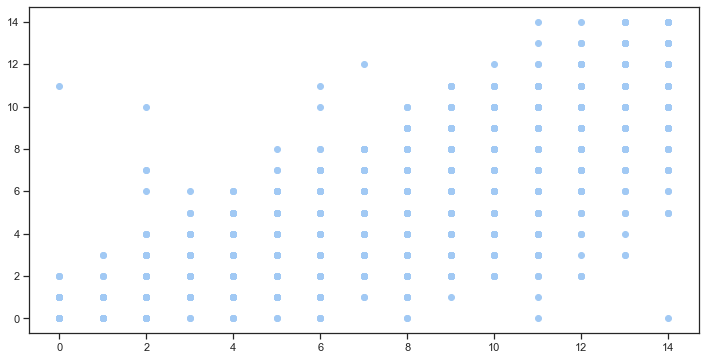

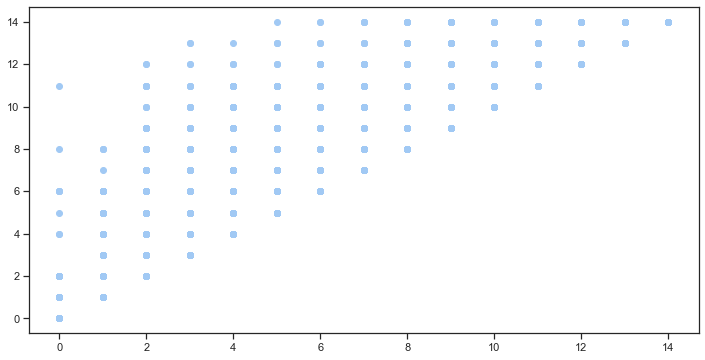

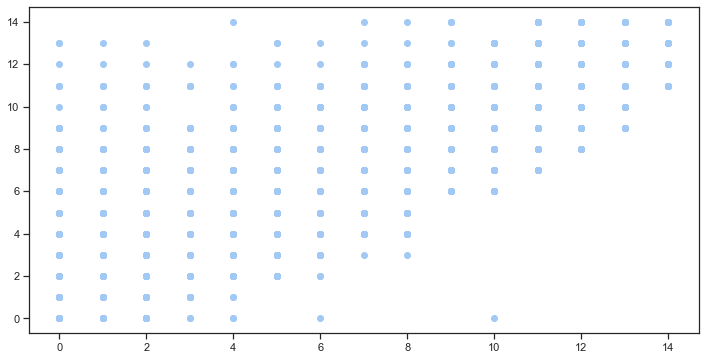

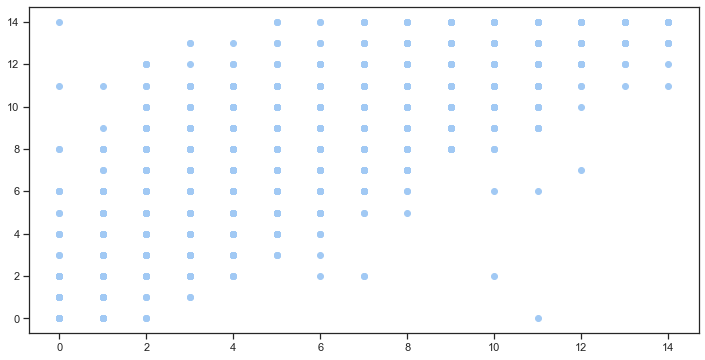

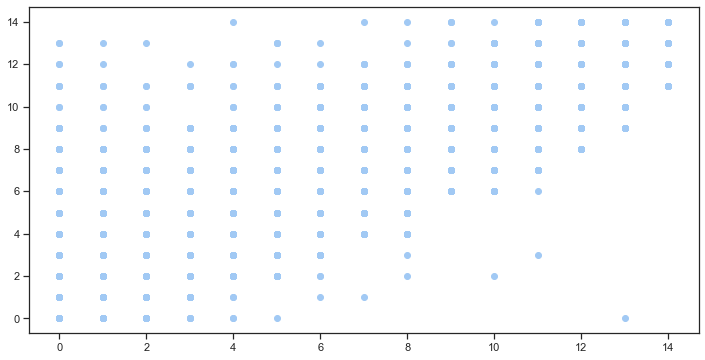

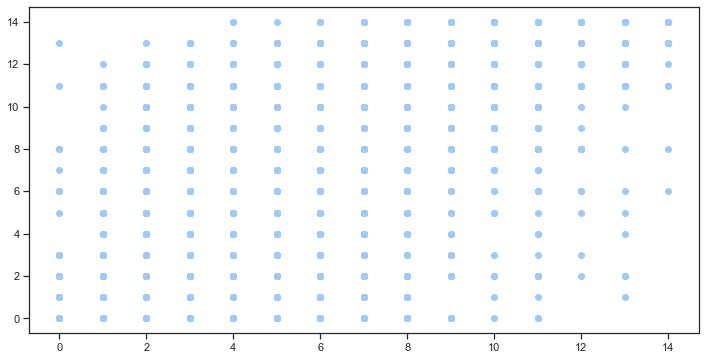

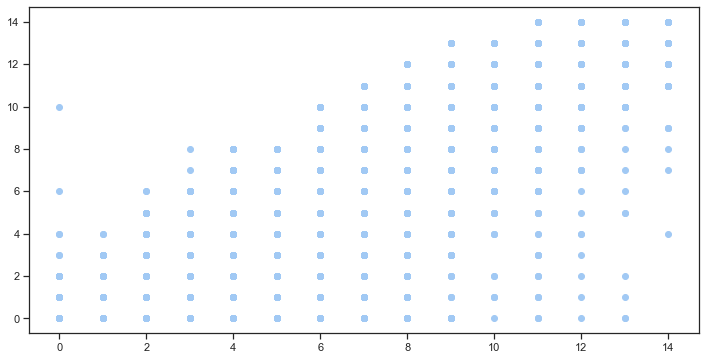

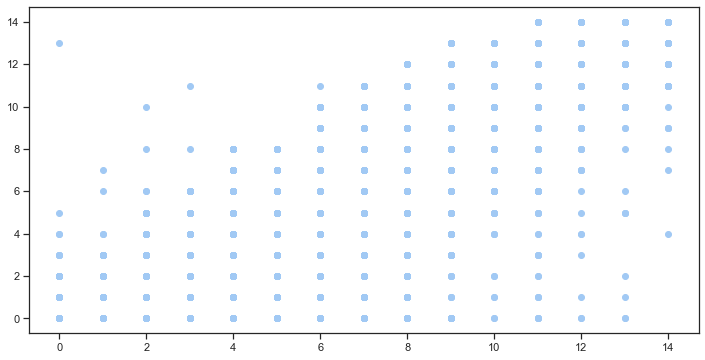

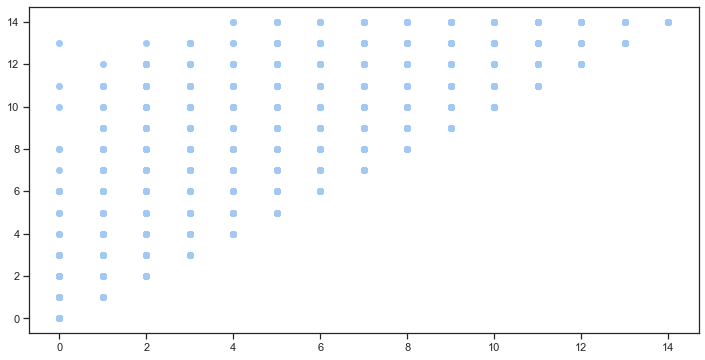

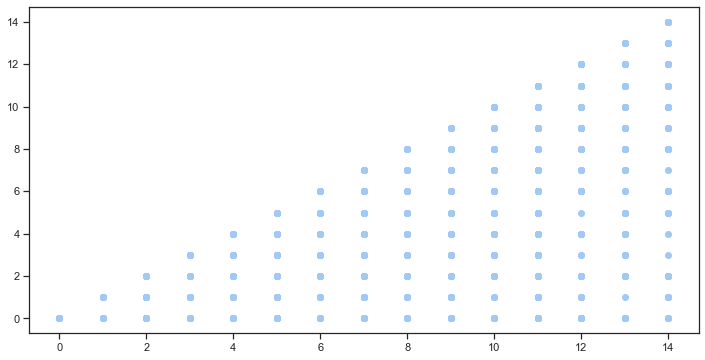

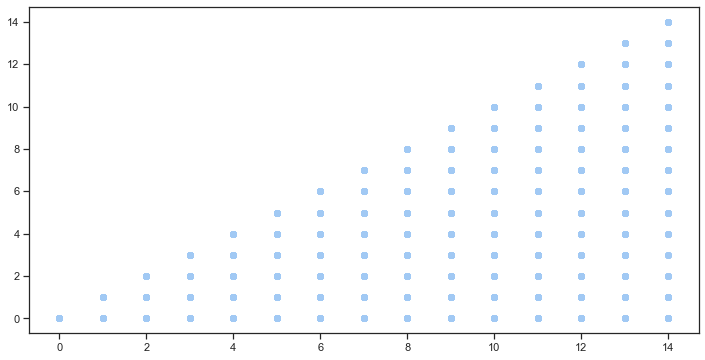

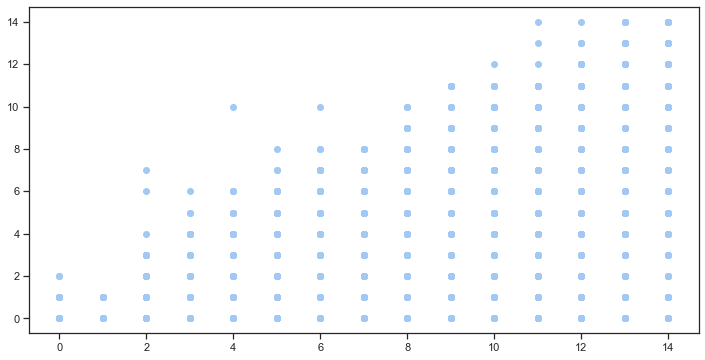

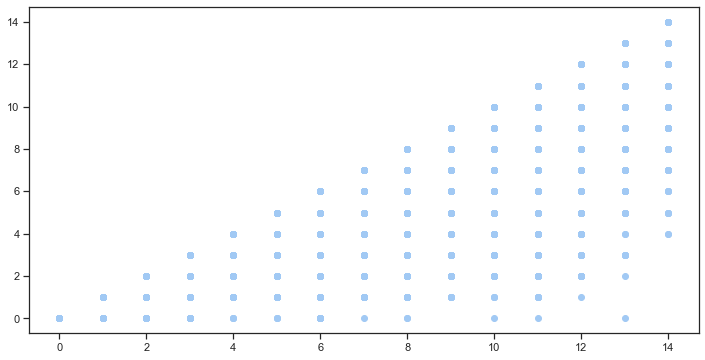

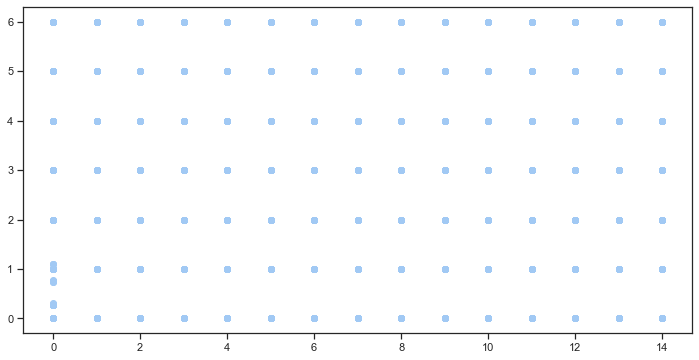

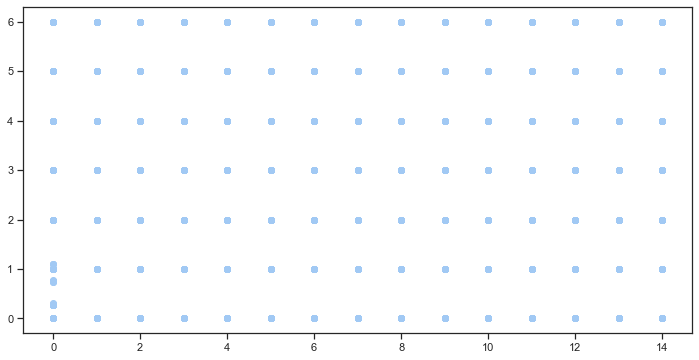

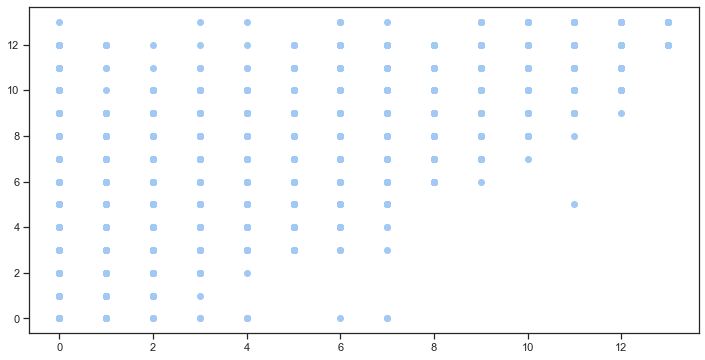

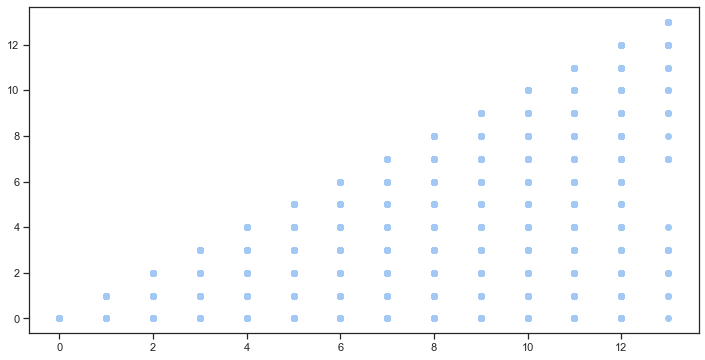

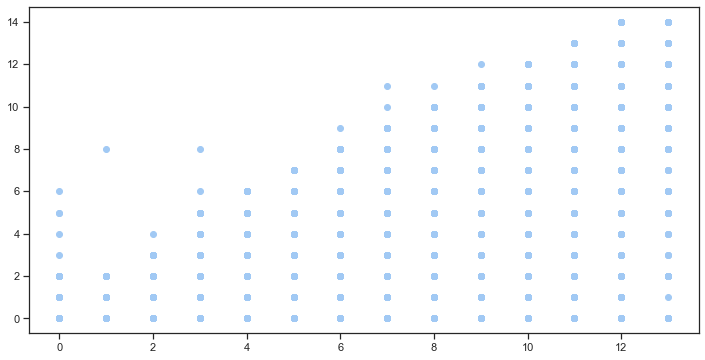

In [29]:
#for variables with strong correlation (close to 1 in absolute value)
plt.scatter(data_num['num9'], data_num['num11'])
plt.show()

plt.scatter(data_num['num9'], data_num['num12'])
plt.show()

plt.scatter(data_num['num11'], data_num['num9'])
plt.show()

plt.scatter(data_num['num11'], data_num['num13'])
plt.show()

plt.scatter(data_num['num12'], data_num['num9'])
plt.show()

plt.scatter(data_num['num12'], data_num['num13'])
plt.show()

plt.scatter(data_num['num13'], data_num['num9'])
plt.show()

plt.scatter(data_num['num13'], data_num['num11'])
plt.show()

plt.scatter(data_num['num13'], data_num['num12'])
plt.show()

plt.scatter(data_num['num13'], data_num['num14'])
plt.show()

plt.scatter(data_num['num14'], data_num['num9'])
plt.show()

plt.scatter(data_num['num14'], data_num['num11'])
plt.show()

plt.scatter(data_num['num14'], data_num['num12'])
plt.show()

plt.scatter(data_num['num14'], data_num['num13'])
plt.show()

plt.scatter(data_num['num14'], data_num['num18'])
plt.show()

plt.scatter(data_num['num15'], data_num['num18'])
plt.show()

plt.scatter(data_num['num17'], data_num['num19'])
plt.show()

plt.scatter(data_num['num17'], data_num['num21'])
plt.show()

plt.scatter(data_num['num17'], data_num['num25'])
plt.show()

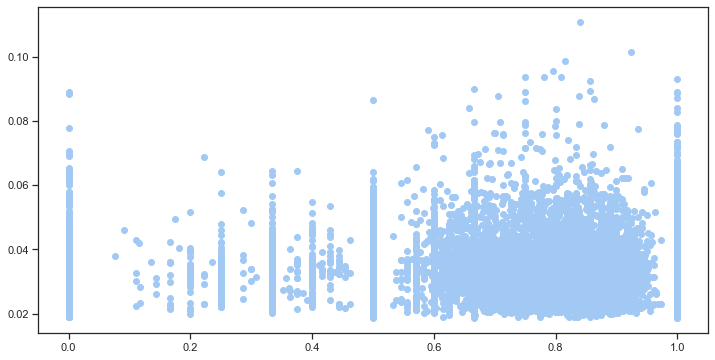

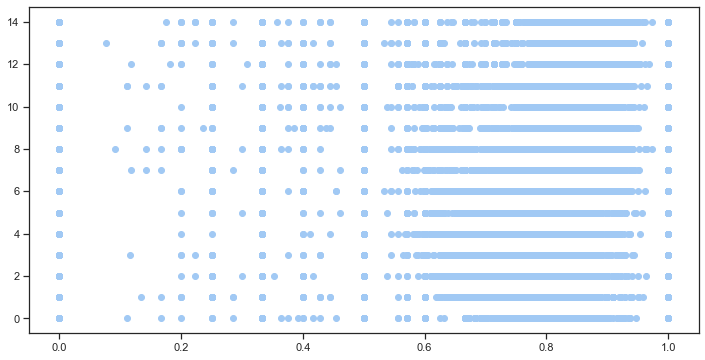

In [30]:
#for variables with weak correlation (close to 0 in absolute value)
plt.scatter(data_num['num3'], data_num['num26'])
plt.show()

plt.scatter(data_num['num3'], data_num['num13'])
plt.show()



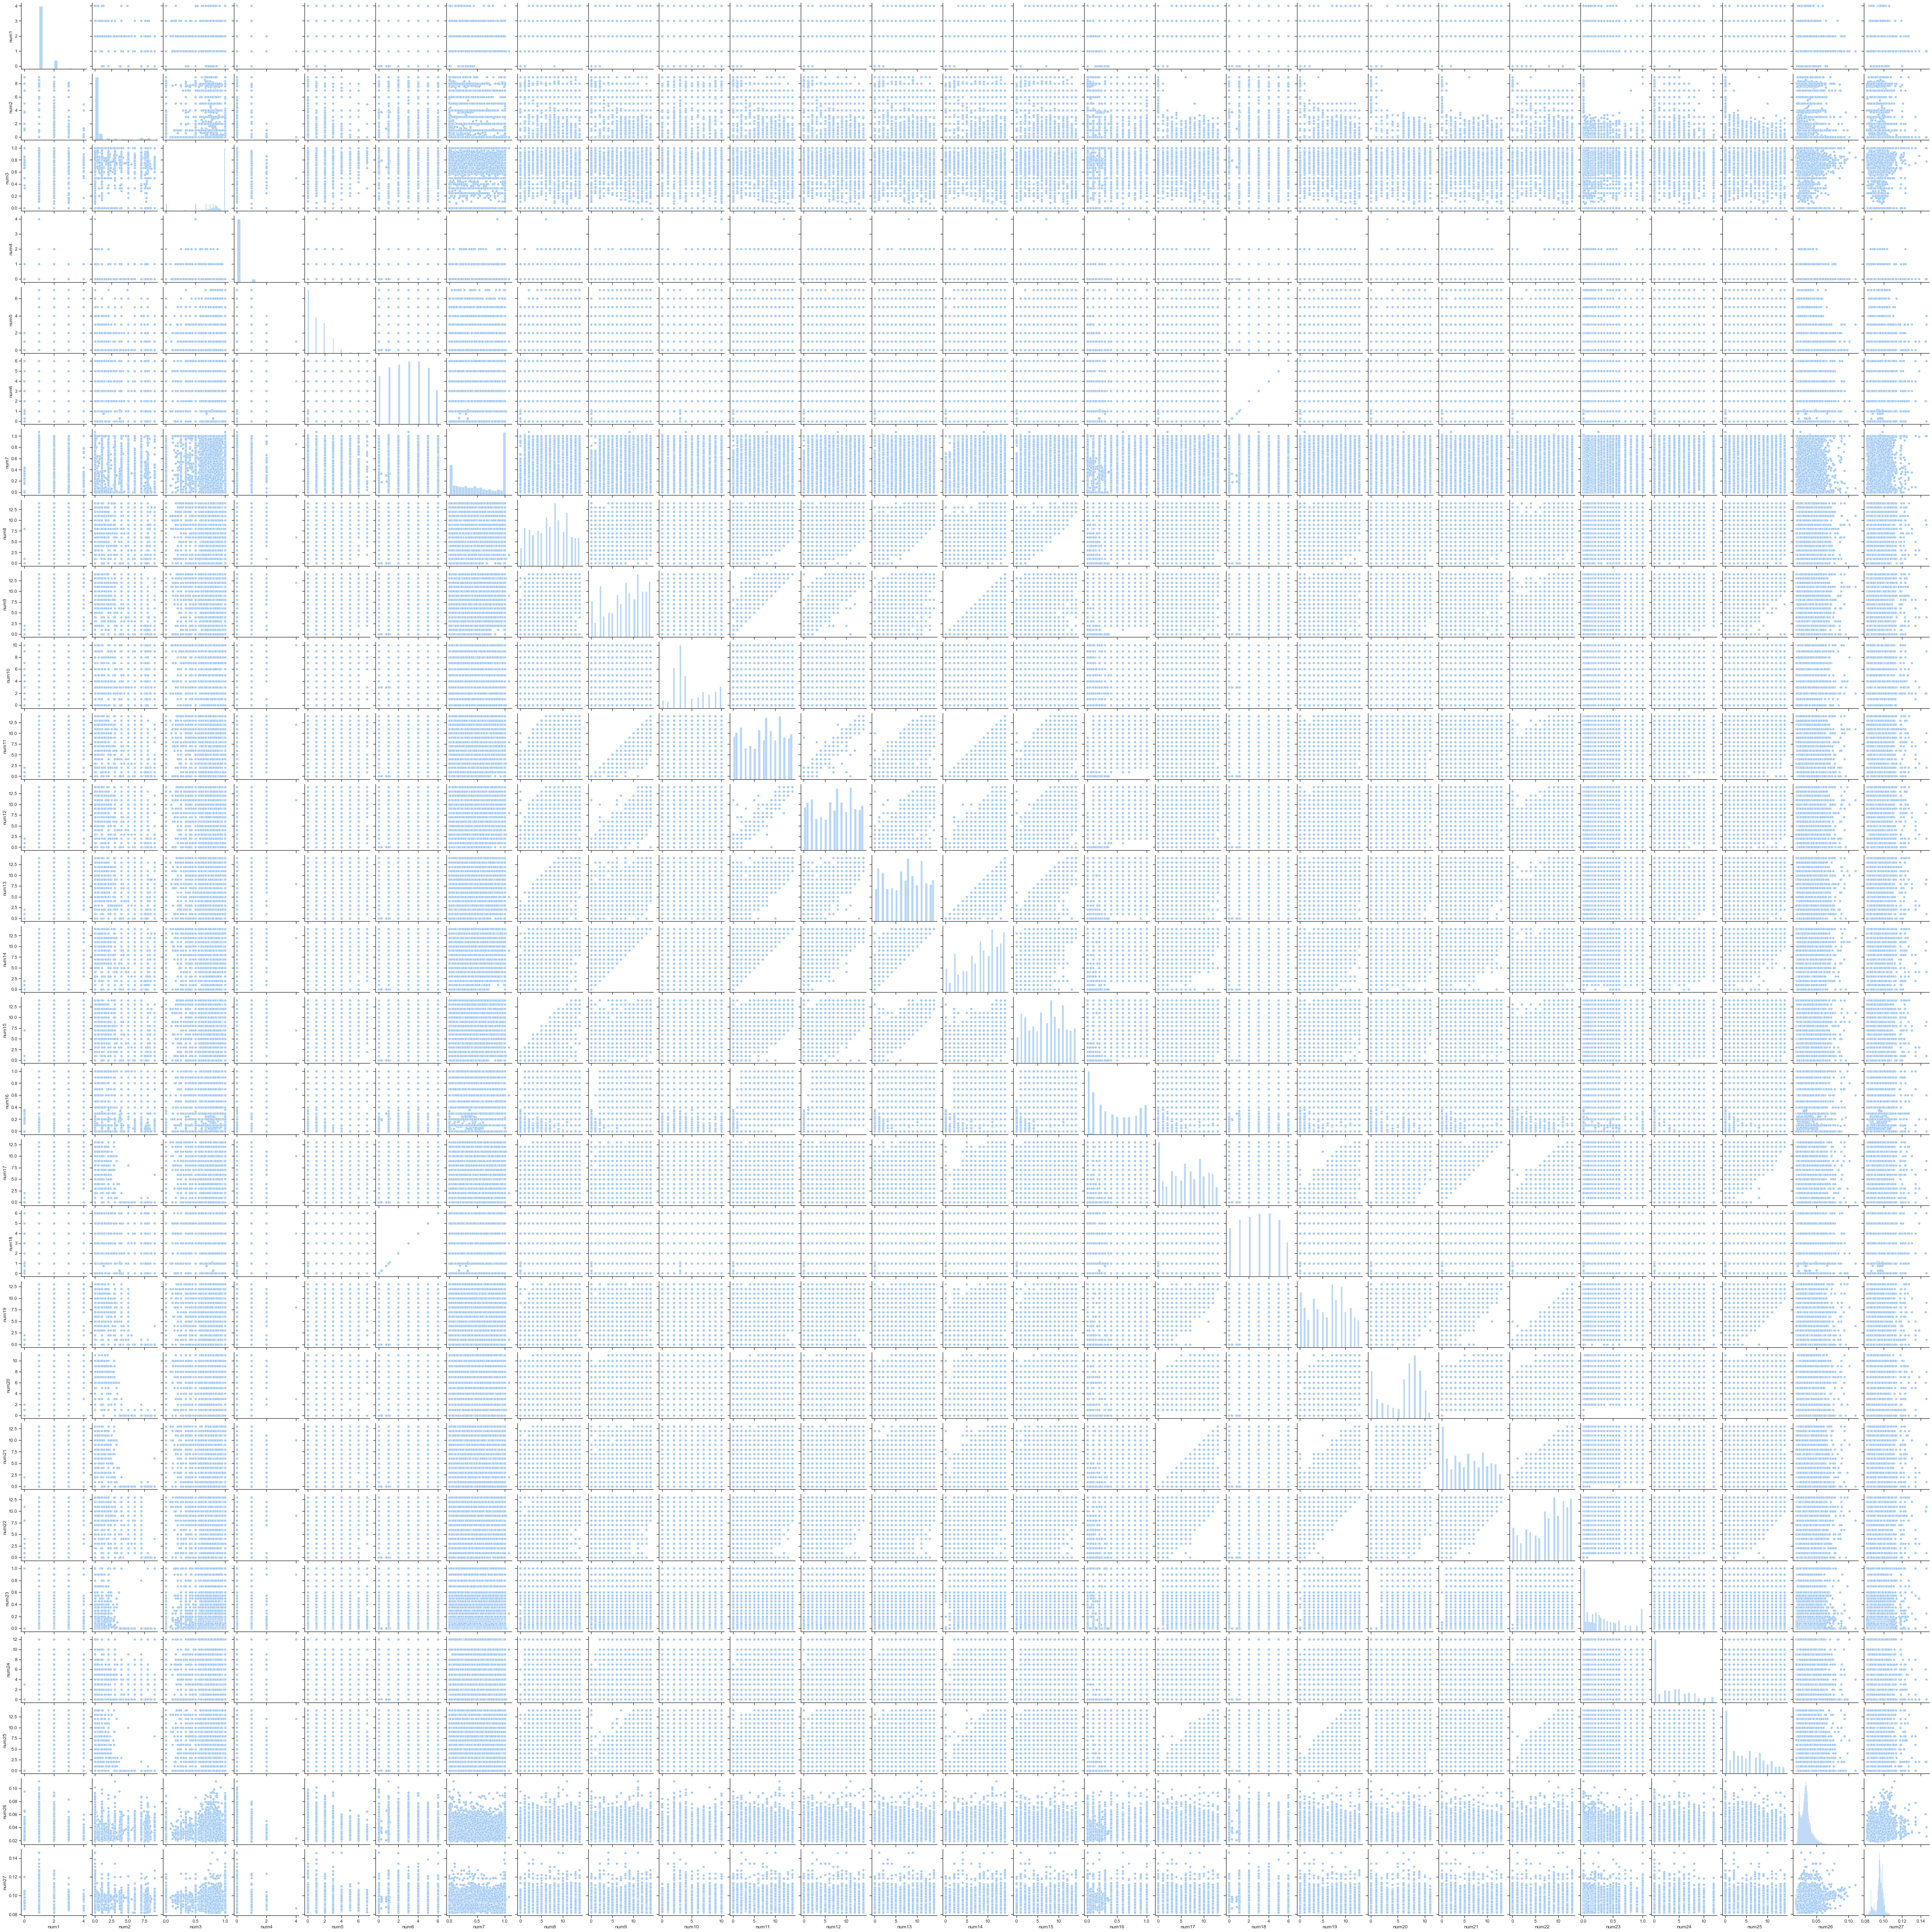

In [31]:
sns.pairplot(data_num)

HEAT MAP FOR ALL VARIABLES

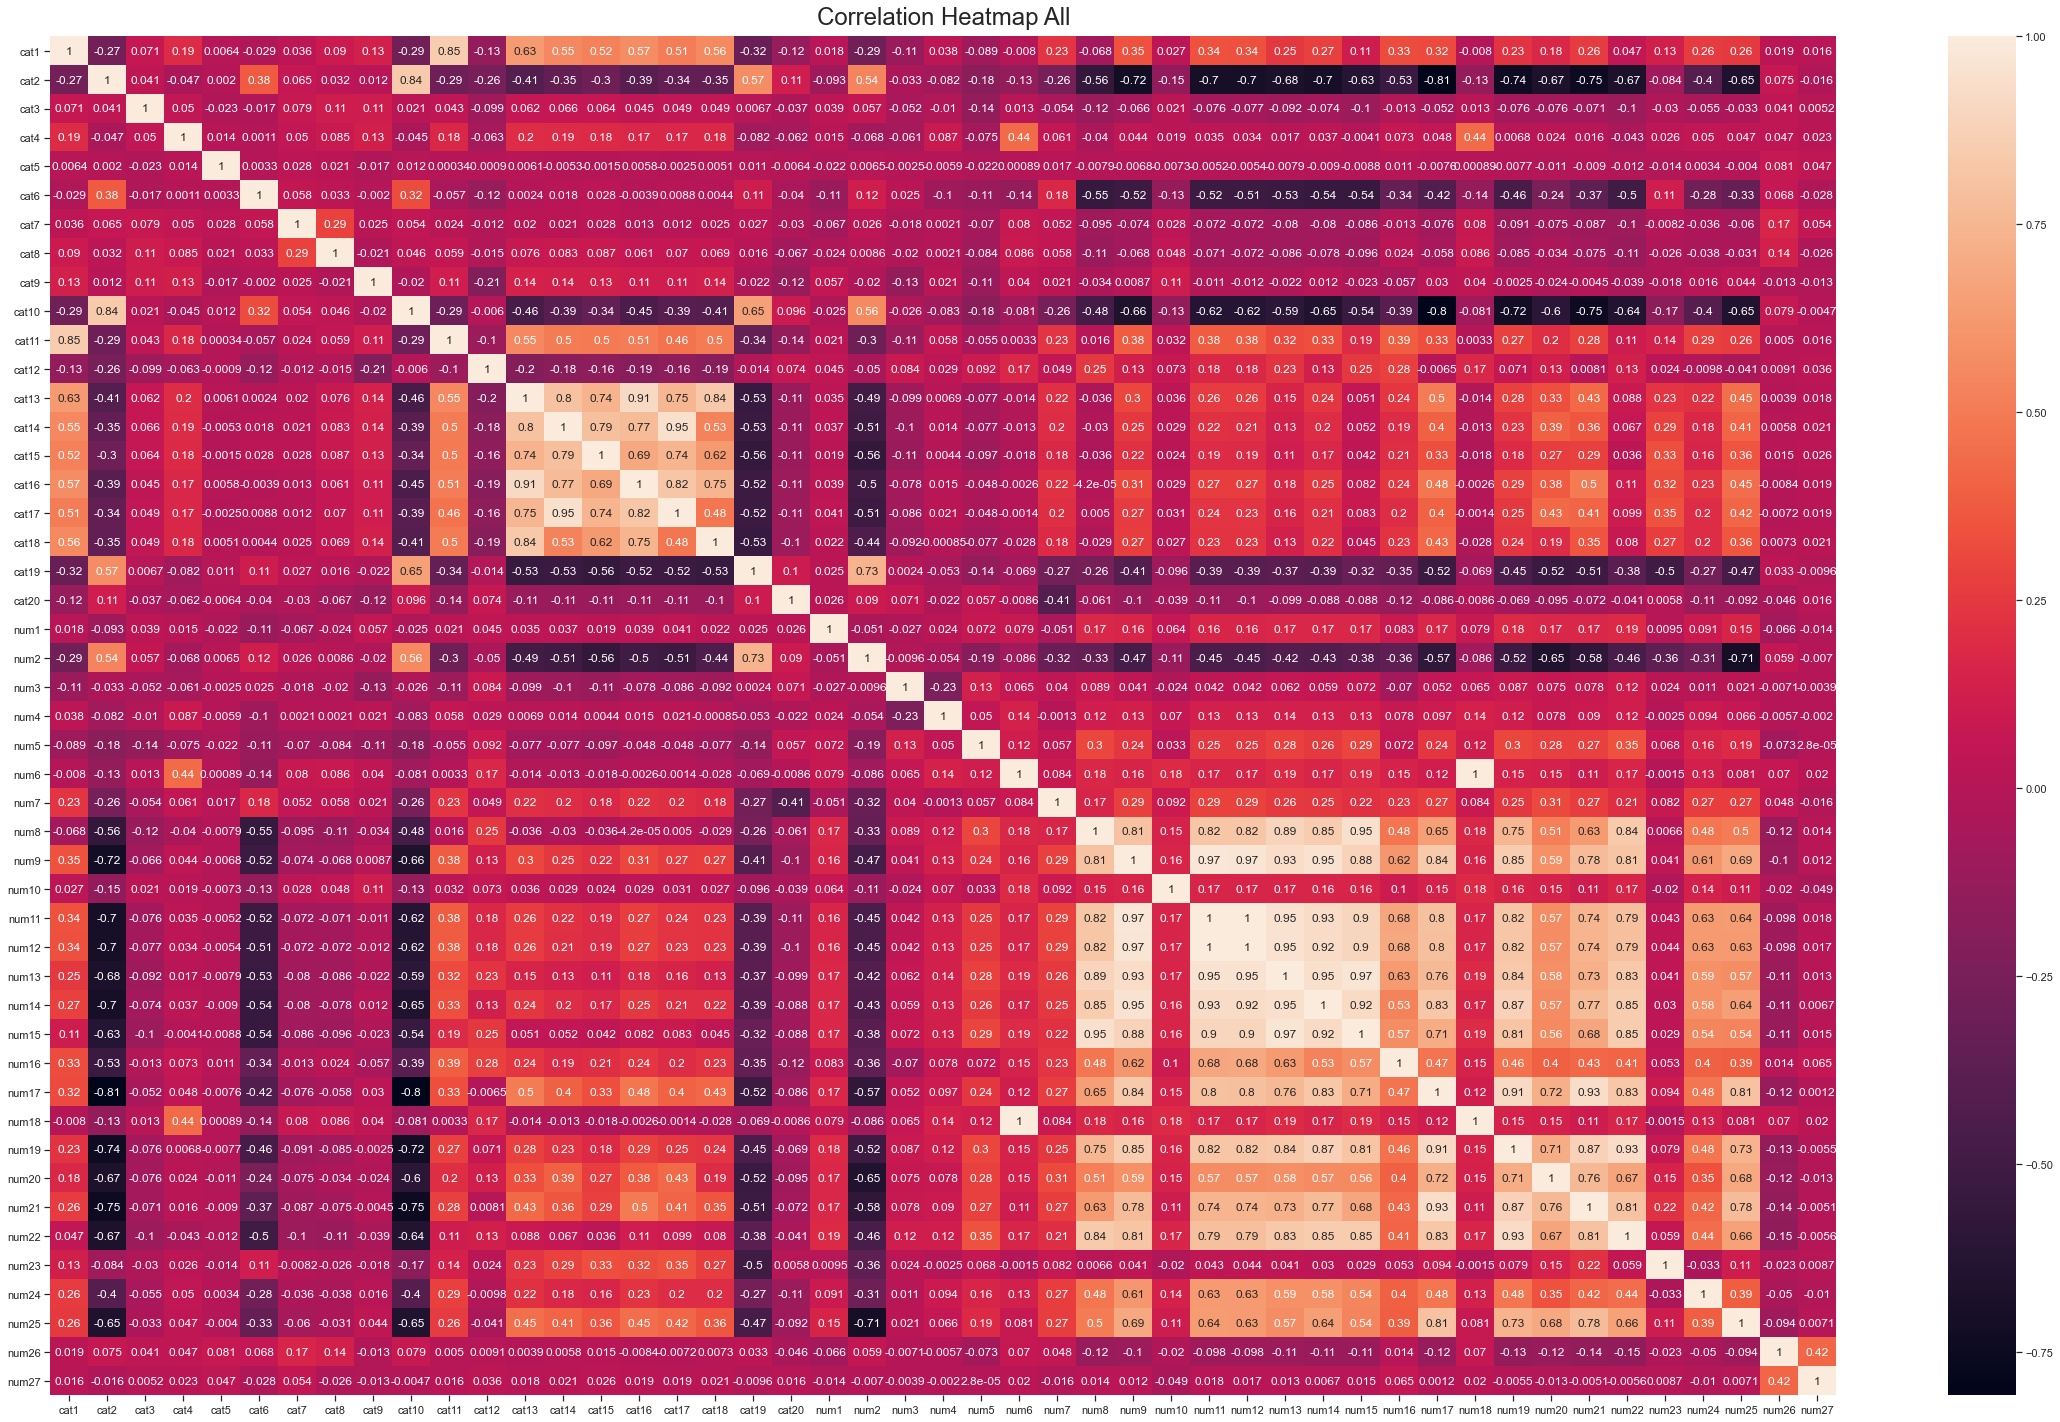

In [32]:
data = df.iloc[:,0:48]
plt.figure(figsize=(40, 25))
heatmap=sns.heatmap(data.corr(method='spearman'), annot=True,yticklabels=data.columns,xticklabels=data.columns)
heatmap.set_title('Correlation Heatmap All', fontdict={'fontsize':24}, pad=12);

In [33]:
#HEAT-MAP
correlation_matrix = df.corr()
df.corr()

,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,...,num18,num19,num20,num21,num22,num23,num24,num25,num26,num27
cat1,1.000000,-0.368248,0.052514,0.186996,0.006803,-0.050558,0.045010,0.080097,0.113957,-0.334374,...,0.017087,0.282093,0.257275,0.294166,0.126847,0.114889,0.279168,0.274472,0.008339,0.006774
cat2,-0.368248,1.000000,0.053377,-0.067965,0.001210,0.324560,0.037113,0.036188,0.006488,0.811651,...,-0.134858,-0.763192,-0.758876,-0.763977,-0.708316,-0.035699,-0.388874,-0.645268,0.065498,-0.012258
cat3,0.052514,0.053377,1.000000,0.048946,-0.028470,-0.012657,0.090378,0.126332,0.094965,0.027143,...,0.016884,-0.072324,-0.076237,-0.066455,-0.106412,-0.001778,-0.041392,-0.025128,0.035472,-0.005923
cat4,0.186996,-0.067965,0.048946,1.000000,0.016398,-0.009736,0.049478,0.085581,0.124986,-0.051841,...,0.438253,0.009326,0.034930,0.011843,-0.032392,0.021560,0.053699,0.042005,0.038732,0.010751
cat5,0.006803,0.001210,-0.028470,0.016398,1.000000,-0.001400,0.020238,0.032372,-0.016301,0.011184,...,0.003511,-0.007855,-0.011722,-0.009403,-0.011602,-0.015718,0.004252,-0.004972,0.076736,0.033459
cat6,-0.050558,0.324560,-0.012657,-0.009736,-0.001400,1.000000,0.010149,0.014391,0.007203,0.281970,...,-0.147315,-0.434325,-0.205836,-0.353182,-0.442197,0.136169,-0.266597,-0.337324,0.043628,-0.021595
cat7,0.045010,0.037113,0.090378,0.049478,0.020238,0.010149,1.000000,0.307384,0.022789,0.025179,...,0.070882,-0.043438,-0.052346,-0.039743,-0.061120,0.010220,-0.020232,-0.020204,0.119408,0.029357
cat8,0.080097,0.036188,0.126332,0.085581,0.032372,0.014391,0.307384,1.000000,-0.020857,0.044358,...,0.077933,-0.093089,-0.034732,-0.085211,-0.113499,-0.022274,-0.030358,-0.043878,0.098570,-0.063429
cat9,0.113957,0.006488,0.094965,0.124986,-0.016301,0.007203,0.022789,-0.020857,1.000000,-0.016852,...,0.009396,-0.014996,-0.029276,-0.012674,-0.059726,0.000935,0.017864,0.044916,-0.005776,-0.013644
cat10,-0.334374,0.811651,0.027143,-0.051841,0.011184,0.281970,0.025179,0.044358,-0.016852,1.000000,...,-0.080306,-0.694851,-0.601112,-0.713055,-0.615535,-0.119924,-0.363323,-0.607087,0.063761,-0.009145
